# trackastra v2 090326 — bursts through the distribution, one trench at a time

A **pair-free, time-free** route to bursts. Section 7 of `trackastra_figures_090326.ipynb` asks
what the distribution of per-cell-frame fluorescence looks like for a **gene**. This notebook
asks it for a single **kymograph**, so a trench is compared to *itself* rather than to the
population it happens to sit in.

Nothing here reads a cell-pair table. `mmtrack.bursts` is entirely pair-free, and the only frame
loaded is the annotated **cell** table via `F.load_cells()` — which is why that loader exists,
rather than calling `load_annotated()` and discarding a 65 MB second return.

### Units: raw a.u., not a.u./ms

Every figure below is **`intensity_mean_fluor`**, the mean pixel value inside the cell mask on
the background-subtracted channel, in raw a.u. — *not* divided by exposure.

That is free, not a compromise. `fluor_exposure_ms` is **one constant per experiment** (verified
in the load cell), so within a kymograph — and within a `(gene, experiment)`, the scope
`compute_baselines` uses — dividing by it is an exactly affine rescale. Every median, MAD,
quartile and percentile scales by the same factor, so **no verdict changes**: measured, 0
disagreements across all 255 kymographs on all eight count columns. Only the axis units differ.

It matters only when pooling **across** experiments, since every gene but murQ spans 2–3 exposure
settings (150/250/450/500 ms). Two consequences:

- `backdrop='gene'` pools a gene's experiments, and warns when handed a raw column.
- §1's `normalize='minmax'` / `'robust'` sets are **bit-identical** under either unit, because
  they rescale within `(gene, experiment)`. Only the absolute set differs — and `figures.md` §3
  measures the raw scale as *tighter* than per-ms for 5 of 10 genes, since exposure is confounded
  with acquisition.

**For a cross-gene or cross-experiment number, quote the 090326 notebook**, which is in a.u./ms.

### What the reference lines are

Two vertical lines: the trench's own **p95**, and its `(gene, experiment)`'s p95.

**A trench's own p95 is a quantile, not an outlier test.** ~5% of any trench's cell-frames sit
above it by construction — measured, the fraction runs 0.0488 to 0.0909 with median 0.0513, and
that spread is interpolation and ties at small `n`, not signal. So it cannot say "this trench has
no bright cells", it cannot pass the constitutive control, and counting above it counts `0.05·n`.

It is still the right line to *draw*: "here is the top 5% of this trench" is what makes a
histogram readable and tells you which cells to open in the viewer. The informative number in
each legend is the **(gene, experiment)-scoped** count — how many of this trench's cell-frames
land in its own *acquisition's* top 5%, which for a dim trench is legitimately 0. That bar is per
acquisition, never pooled over a gene's replicates (28 groups for 10 genes), which is why the
legend reads `gene×exp`.

The rule that actually discriminates is **Tukey's fence**, `Q3 + 1.5·IQR`, and it lives in §2's
table and §5's comparison rather than on the figures. Pass `bars='tukey'` to draw it.

### ⚠ What a distribution cannot do

Throwing time away throws away the **rise**, and prominence — not height — is what separates a
burst from a constitutive gene (`bursts.md` §4). A flat-high trace has no rises in it whatever
its brightness.

So nothing here counts events, and this notebook writes no event CSV. Measured on the canonical
clean burst, araB 003/1598: the fence flags **44 cell-frames over 33 distinct time_frames** —
37–66, then a **15-frame gap**, then 81, 86 and 87 (one real cell, track 50, areas 261–344 px²).
So a flagged count mixes magnitude, duration *and* the number of co-bright cells, and the flagged
set is not one contiguous episode even here. Counts and distinct-frame counts differ in **112 of
255** trenches, by up to 24. §4 is a worklist and §5 is a corroboration check.

### What is already settled — this notebook is not re-opening it

| attempt | result |
|---|---|
| **v5local** — v5 against a per-trench median/MAD, floored at 25% of the gene's | 181 events vs v5's 118, coverage 43% → 59%, controls intact. **Evaluated, not shipped** |
| **unfloored per-kymograph** | 156 events but **breaks the mazF control** (0.19) |
| **`kymograph_global_scale`** (local centre, global scale) | a measured **no-op**, 89 events |
| **per-*time-frame* baseline** | **rejected** — cannot separate the target from the controls under any window or smoothing. 090326 cell 71 holds a live assert. Do not rebuild it |

The genuinely local-only set is **68 events**, and `bursts.md` §8's closing line is this
notebook's mandate: the per-trench layer "is kept as a viewer layer so the remaining 68 can be
judged by eye."

In [1]:
import os
import sys

REPO_ROOT = '/Users/adrianjuarez/Documents/Covert_lab/repos/mother_machine_cell_tracker'
sys.path.insert(0, REPO_ROOT)          # belt-and-braces; mmtrack is also pip-installed -e
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import mmtrack
assert os.path.realpath(mmtrack.__file__).startswith(os.path.realpath(REPO_ROOT)), (
    f'mmtrack resolves to {mmtrack.__file__}, not this repo.\n'
    f'Fix with:  {sys.executable} -m pip install -e . --no-deps   (run from {REPO_ROOT})')

import mmtrack.figures as F
import mmtrack.bursts as Bu

%load_ext autoreload
%autoreload 2

# ---- CONFIG: the only cell to edit --------------------------------------------------------
FIG_DIR = f'{REPO_ROOT}/notebooks/figures/summary_v2_090326'
SAVE_FIGS = False
DROP_FAILED = True          # False keeps all 23 experiments

# RAW a.u. -- see the header. Within a kymograph the exposure division is an affine rescale
# that changes no verdict, so it only costs us a familiar axis label.
FLUOR = F.RAW_FLUOR_COL     # 'intensity_mean_fluor'
K = 4.0                     # MAD-scale multiplier, for the shipped detector's bar
SCALE_FLOOR_FRAC = 0.25     # floor the local MAD scale at this fraction of the gene's

F.configure(out_dir=FIG_DIR, save=SAVE_FIGS,
            label=F.scope_label(drop_failed=DROP_FAILED), suffix='')

pd.set_option('display.max_rows', 300)
pd.set_option('display.width', 240)
pd.set_option('display.max_colwidth', None)
print(f'figures -> {FIG_DIR}  (save={SAVE_FIGS})')
print(f'fluorescence column: {FLUOR!r}  ->  {F.fluor_label(FLUOR)}')

figures -> /Users/adrianjuarez/Documents/Covert_lab/repos/mother_machine_cell_tracker/notebooks/figures/summary_v2_090326  (save=False)
fluorescence column: 'intensity_mean_fluor'  ->  mean fluorescence inside the cell mask (a.u.)


In [2]:
# Cells only. No pair table is read anywhere in this notebook.
cells = F.load_cells(data_root=REPO_ROOT, drop_failed=DROP_FAILED)

# The working frame. `is_degenerate_mask` is the EXPORTED flag -- computed against the full
# 23-experiment medians -- rather than a re-run of drop_degenerate_masks, which would recompute
# the floor from whatever subset happens to be loaded. On a 1-px mask intensity_mean_fluor is a
# single raw pixel with no averaging, and one such mask can set an entire kymograph's maximum.
clean = cells[~cells['is_degenerate_mask']]

F.describe_scope(cells, 'cells')
F.describe_scope(clean, 'clean')
print(f"{int(cells['is_degenerate_mask'].sum()):,} degenerate masks excluded "
      f'({100 * cells["is_degenerate_mask"].mean():.2f}%)')

# The claim the whole units decision rests on. ONE assert, not three: KYMO_GROUP and
# (gene, experiment) are strict REFINEMENTS of experiment_name -- every one of their groups is a
# subset of an experiment group -- so once this passes, constancy at the finer scopes follows by
# construction. Asserting all three would print three verified facts and check one.
_n = clean.groupby('experiment_name', observed=True)[F.EXPOSURE_COL].nunique()
assert _n.max() == 1, 'exposure varies WITHIN an experiment; the affine argument fails'
print(f'\nexposure constant within each experiment: ok  '
      f'(kymograph and (gene, experiment) follow -- both refine it)')
print(f'exposures present: {sorted(clean[F.EXPOSURE_COL].unique())} ms')

# Sample sizes, because a p95 needs enough observations to mean anything.
_n = clean.groupby(F.KYMO_GROUP, observed=True).size()
print(f'\ncell-frames per kymograph: min {_n.min()}, p5 {_n.quantile(.05):.0f}, '
      f'median {int(_n.median())}, max {_n.max()}')
print(f'  {int((_n < 50).sum())} kymographs below 50 cell-frames, '
      f'{int((_n < 100).sum())} below 100')
print(f'  at n={_n.min()} the "top 5%" is a single cell-frame -- read those rows accordingly')

cells: 81,920 rows | 20 experiments | 10 genes | 255 kymographs | 11,476 unique cells
clean: 81,799 rows | 20 experiments | 10 genes | 255 kymographs | 11,401 unique cells
121 degenerate masks excluded (0.15%)

exposure constant within each experiment: ok  (kymograph and (gene, experiment) follow -- both refine it)
exposures present: [np.int64(150), np.int64(250), np.int64(450), np.int64(500)] ms

cell-frames per kymograph: min 22, p5 59, median 279, max 974
  6 kymographs below 50 cell-frames, 42 below 100
  at n=22 the "top 5%" is a single cell-frame -- read those rows accordingly


---
# 1 — The per-gene distributions

Section 7 of the 090326 notebook, carried forward: `F.plot_fluor_histogram` is where section 10
of the 082026 notebook now lives, so these are calls rather than a rebuild.

Three sets. **Sets 2 and 3 are bit-identical whether the column is raw or per-ms**, because
min–max rescales within `(gene, experiment)` where exposure is constant. Only Set 1, the
absolute axis, differs — and on the raw scale it is no worse: `figures.md` §3 measures the
replicate spread as *tighter* raw than per-ms for 5 of 10 genes, because exposure is confounded
with acquisition.

Pooling a gene's experiments on an absolute axis is still the thing to be careful about. baeS's
pooled skew is **5.85** against a within-experiment skew of **0.95**, because
`DUMM_giTG66_Glucose_012325` sits bodily above its siblings — and that offset is a **pixel-scale**
artefact, not biology: that run was recorded at ~1/3 the linear pixel scale (cells, widths *and*
trenches all ~0.34×), and a per-pixel mean rises when pixels integrate more photons. Nothing in
the pipeline records pixel size.

**Min–max divides by a burst.** In 14 of the 20 `(gene, experiment)` groups holding a detected v2
burst, the brightest cell-frame *is* one of those peaks. So `1.0` means "this acquisition's own
burstiest moment", not a fixed level. `normalize='robust'` (p1–p99) is the alternative.

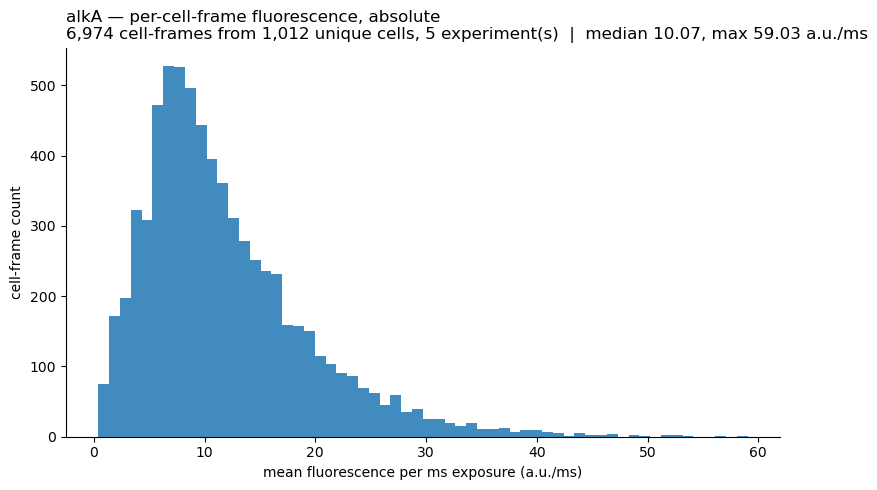

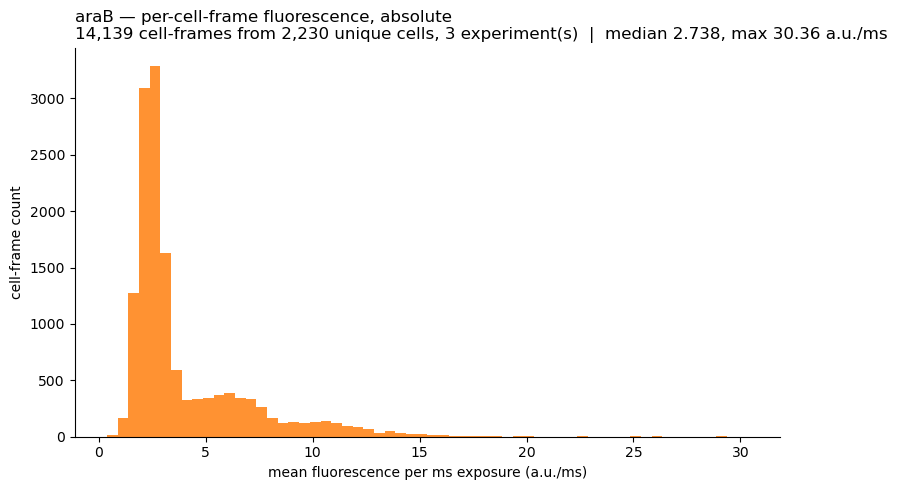

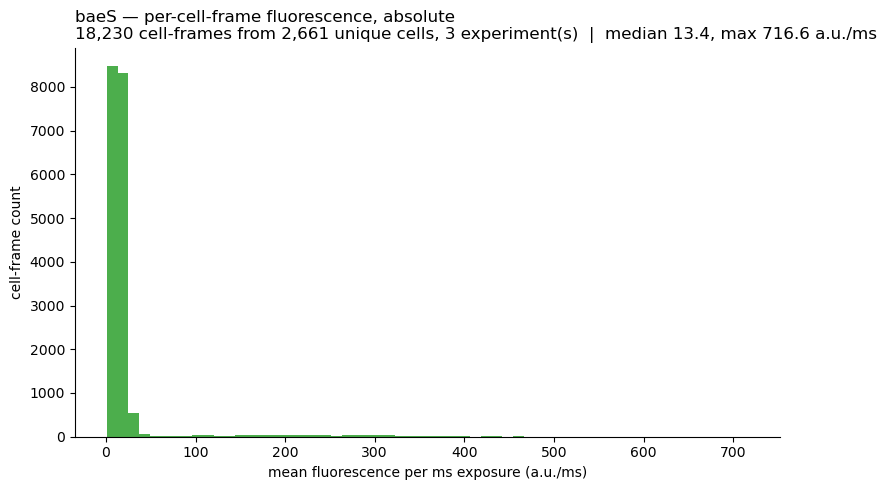

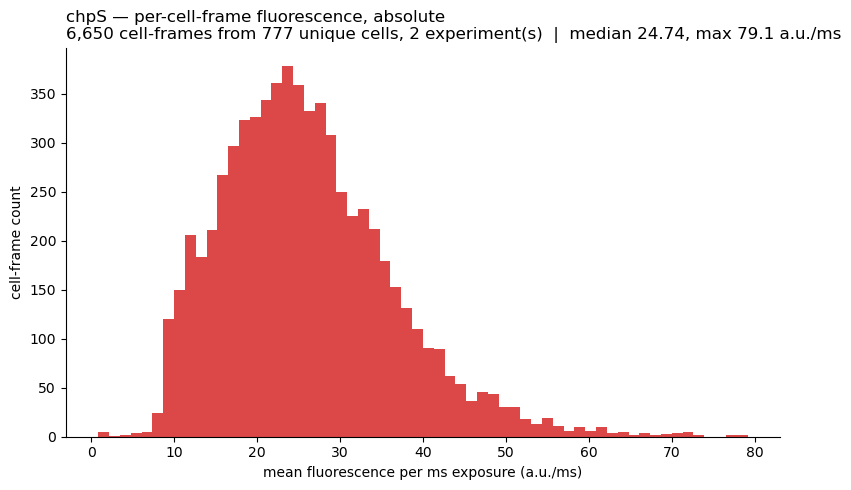

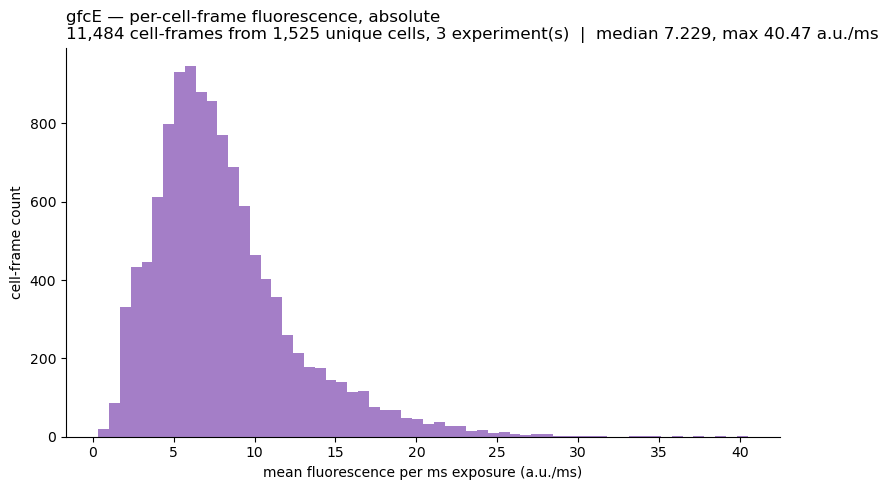

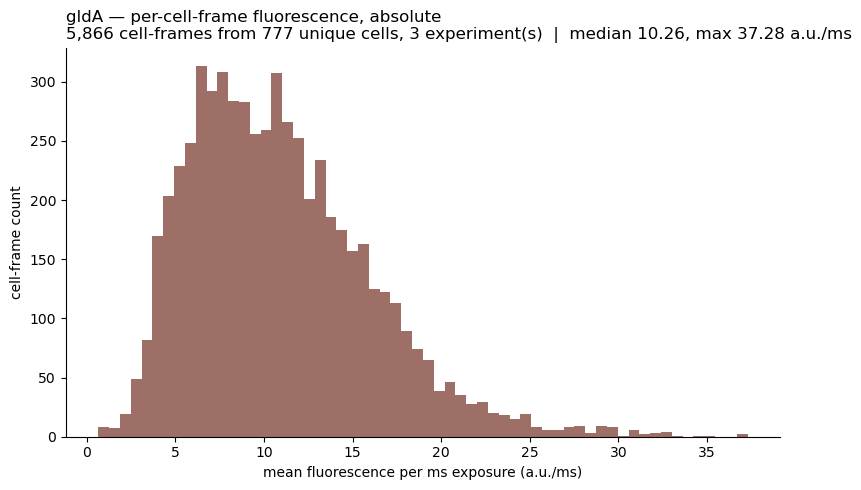

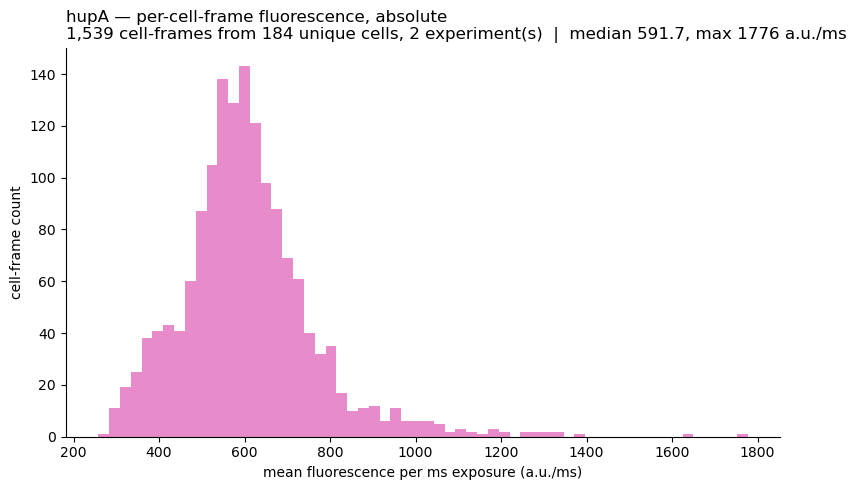

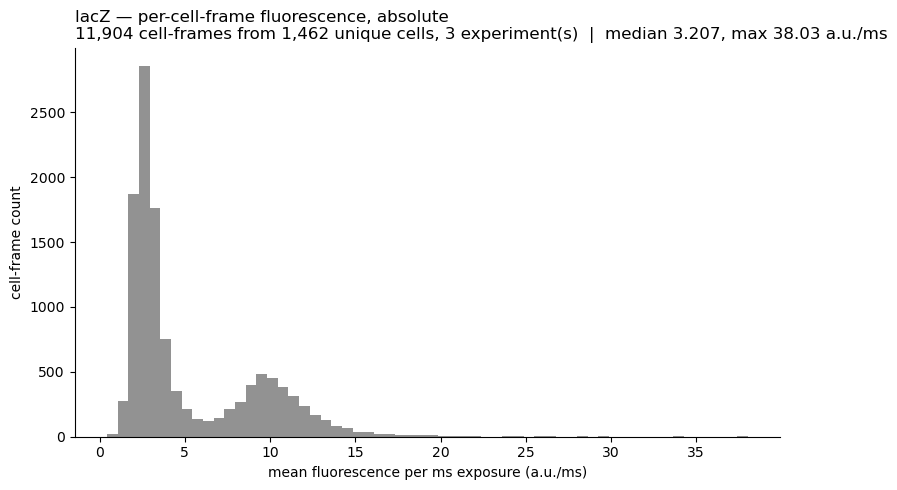

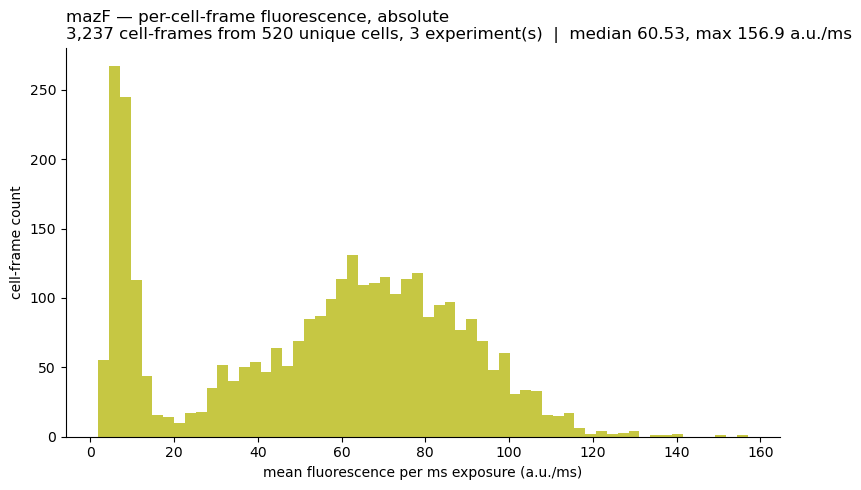

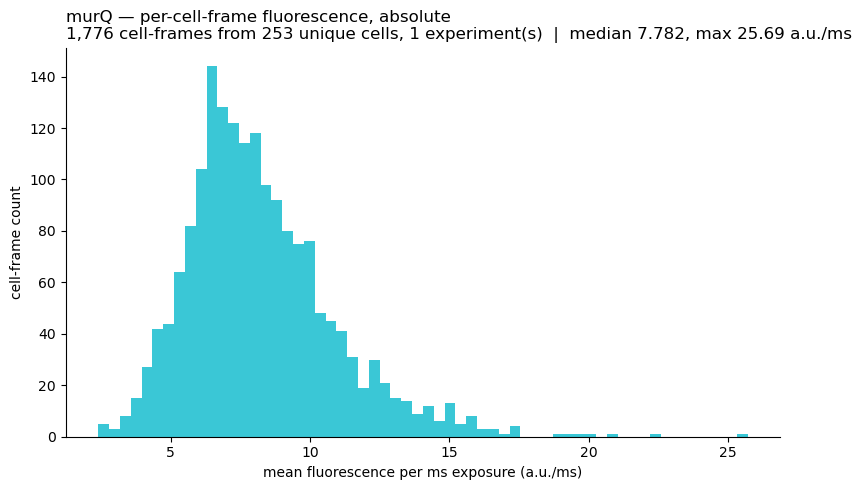

In [3]:
# Set 1 -- absolute raw a.u. Nothing saved.
for _gene in sorted(clean['gene'].dropna().unique()):
    F.plot_fluor_histogram(clean, _gene, value_col=FLUOR, normalize='none', save=False)

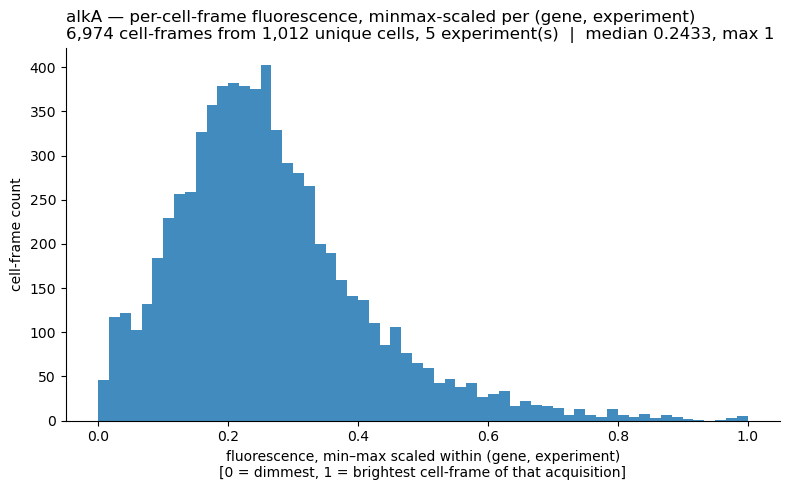

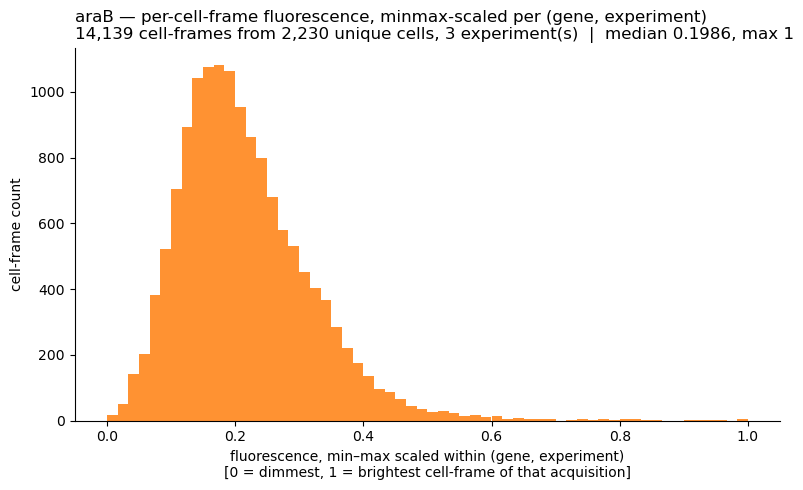

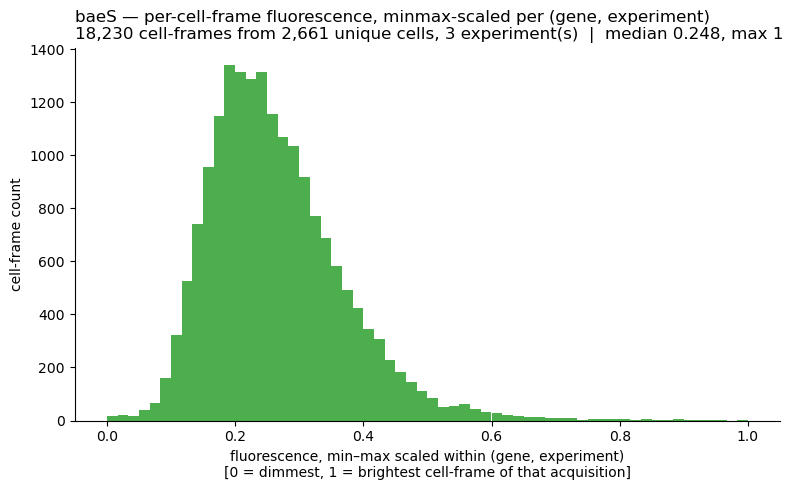

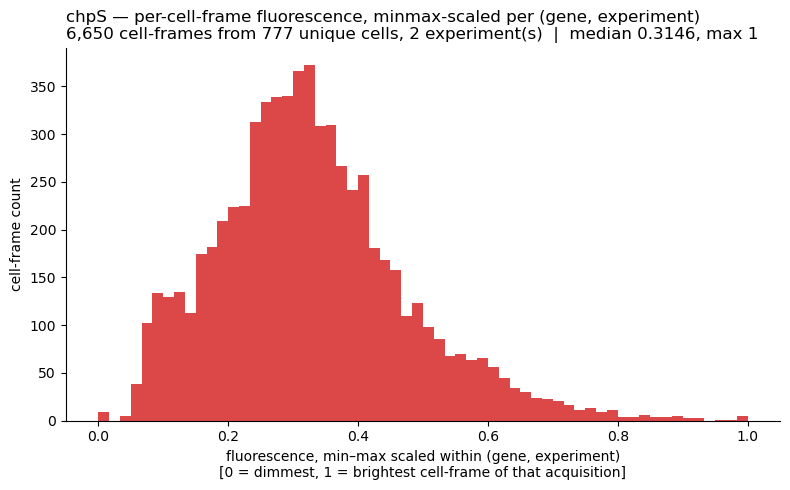

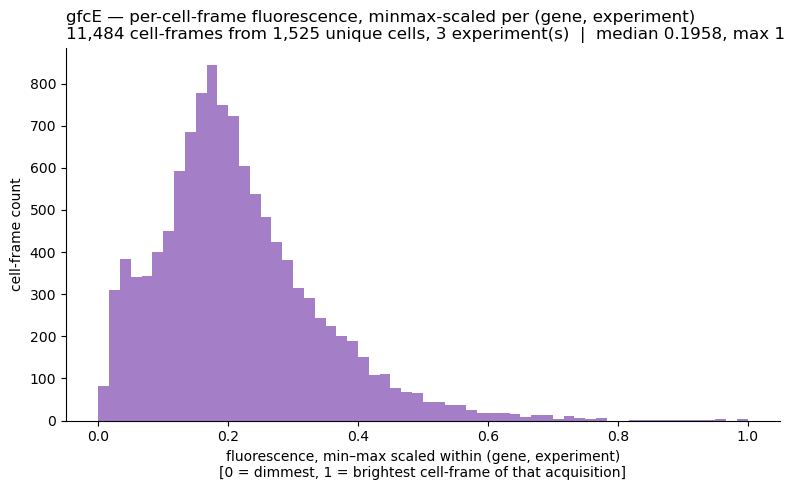

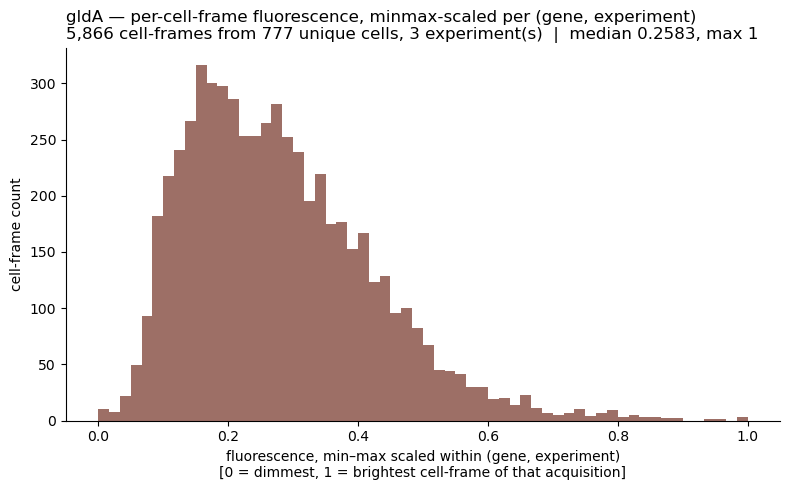

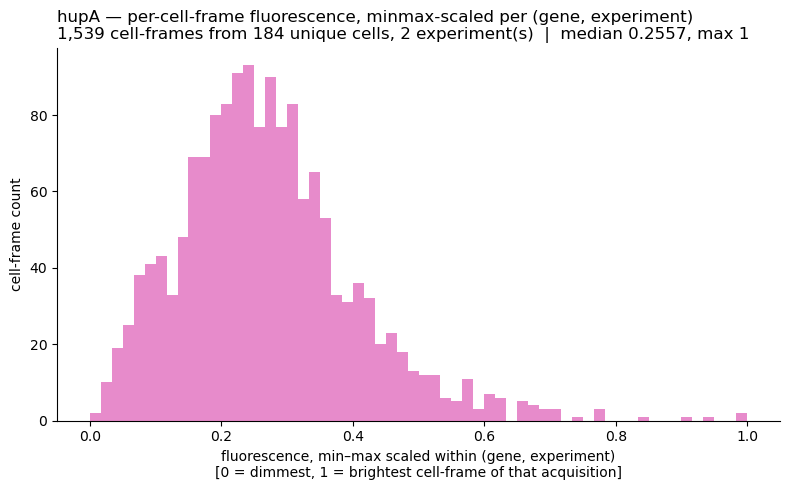

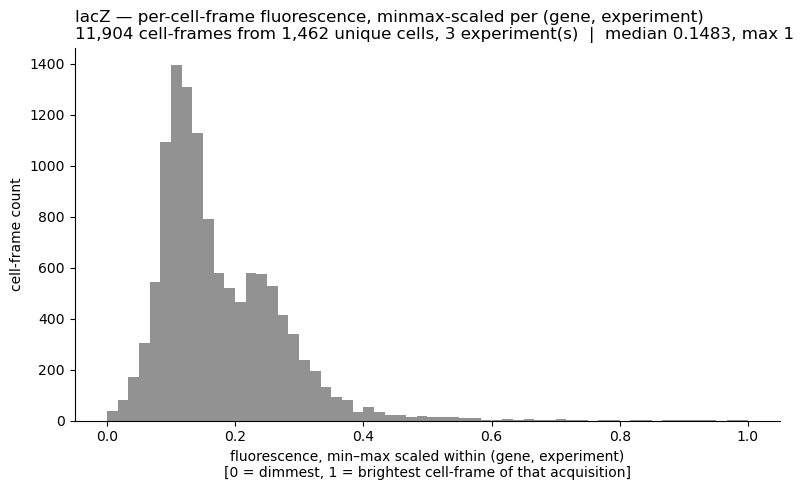

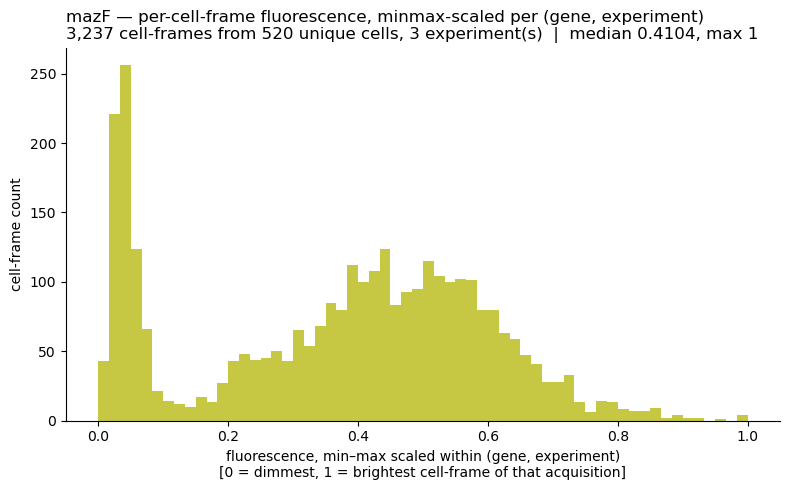

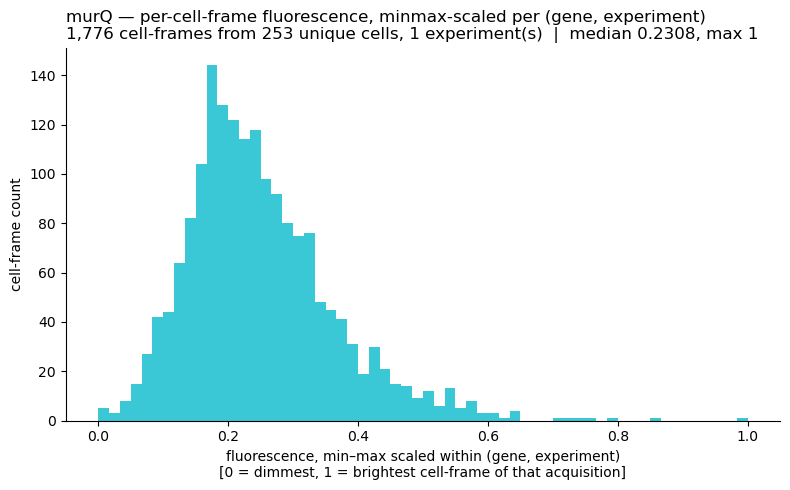

In [4]:
# Set 2 -- min-max within each (gene, experiment). Bit-identical under either unit.
for _gene in sorted(clean['gene'].dropna().unique()):
    F.plot_fluor_histogram(clean, _gene, value_col=FLUOR, normalize='minmax', save=False)

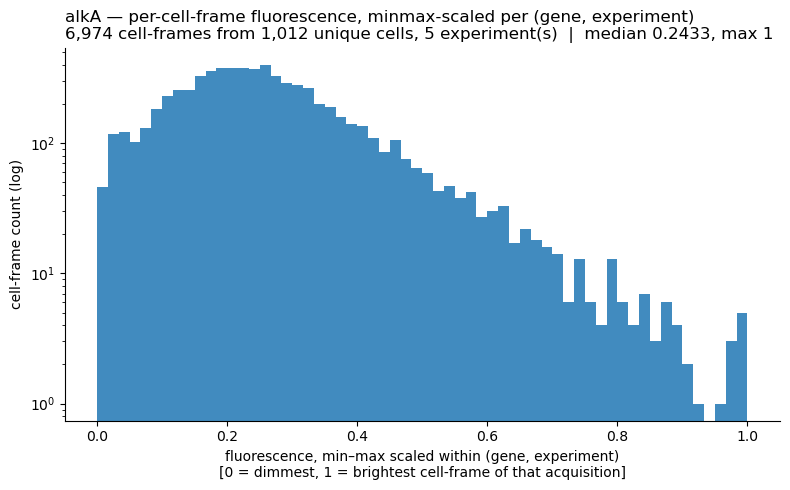

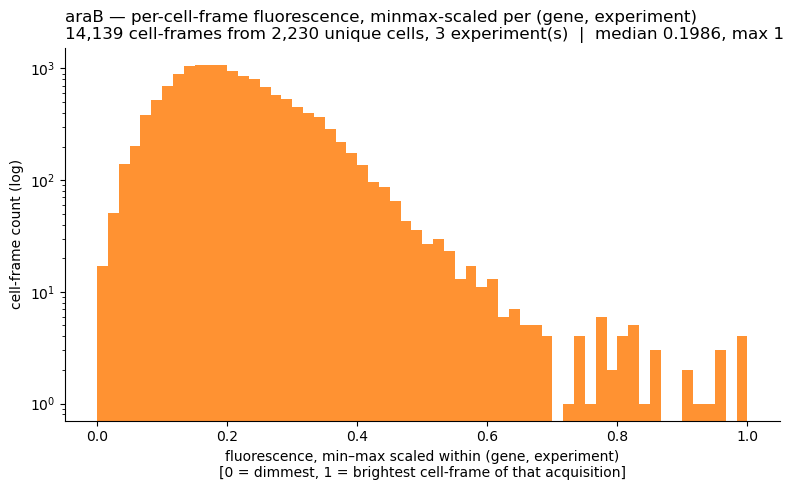

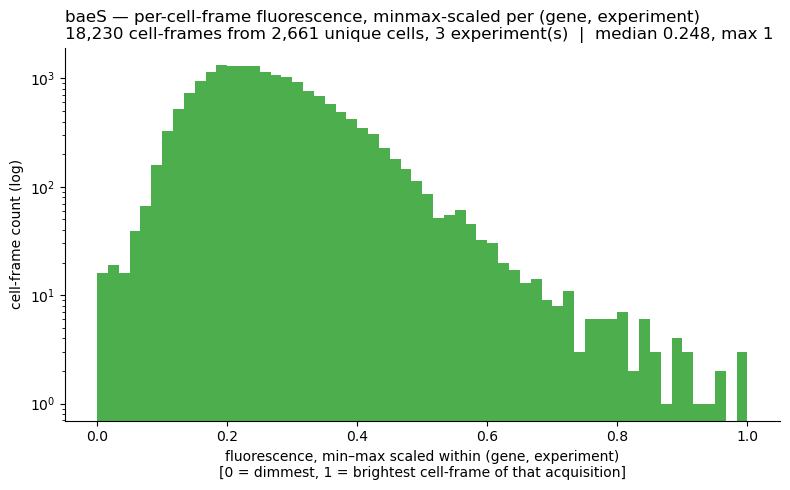

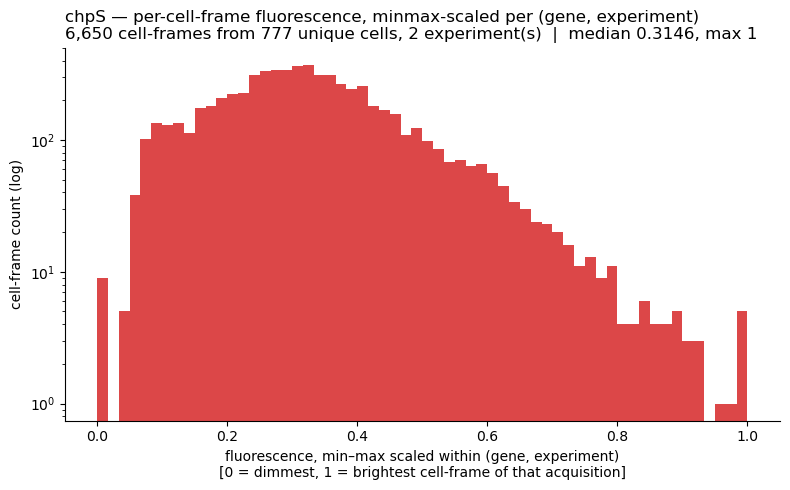

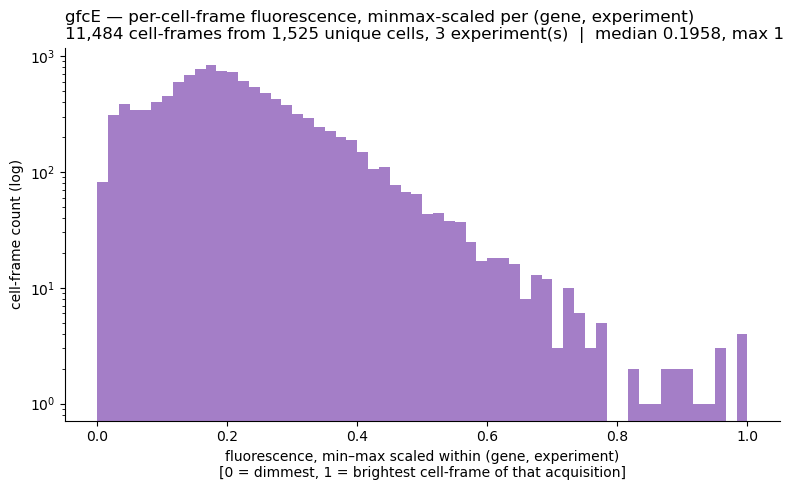

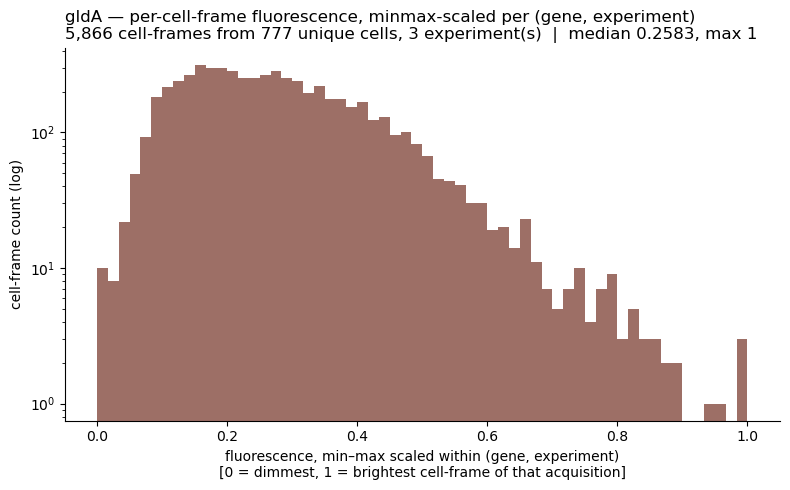

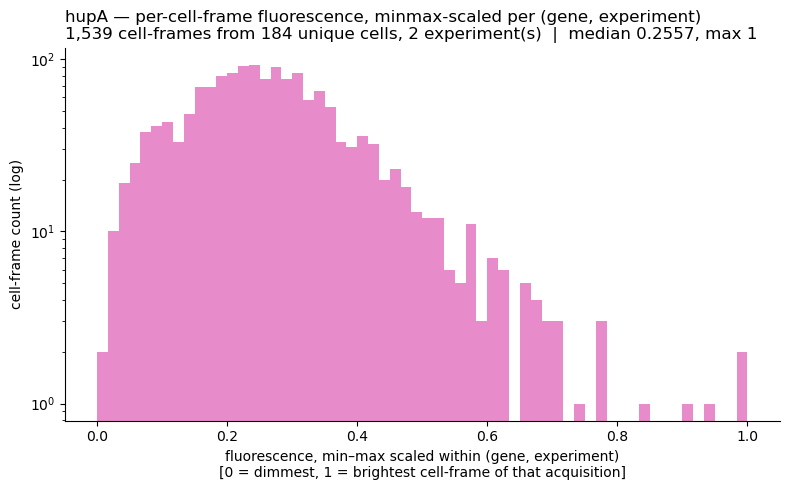

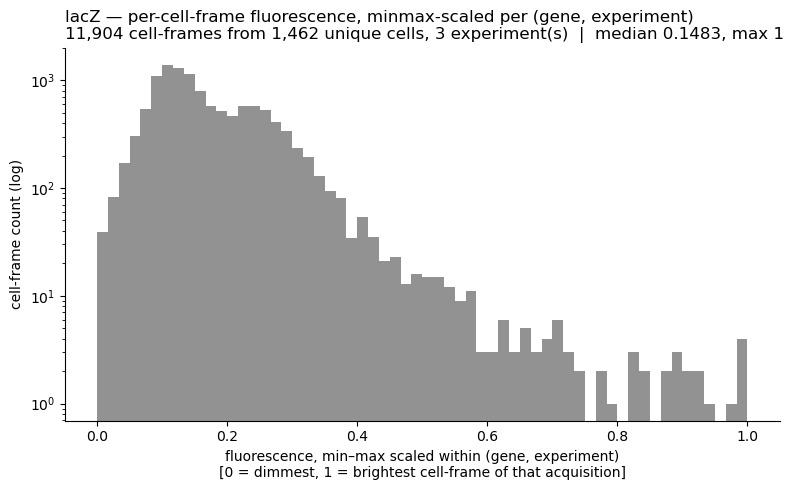

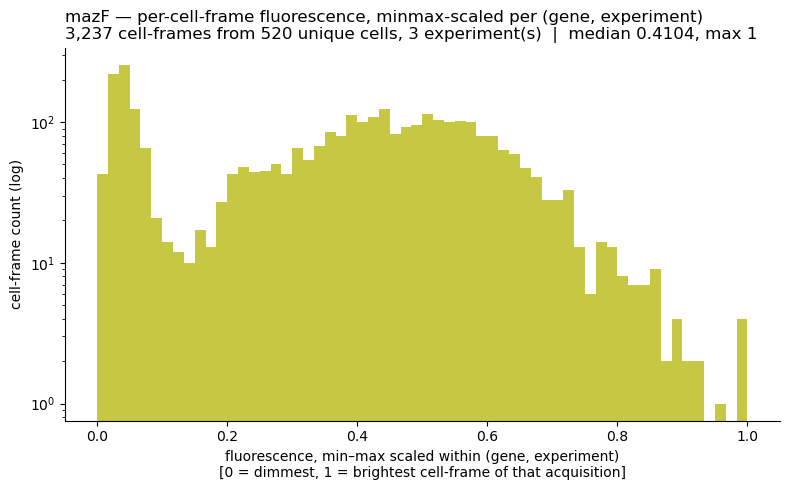

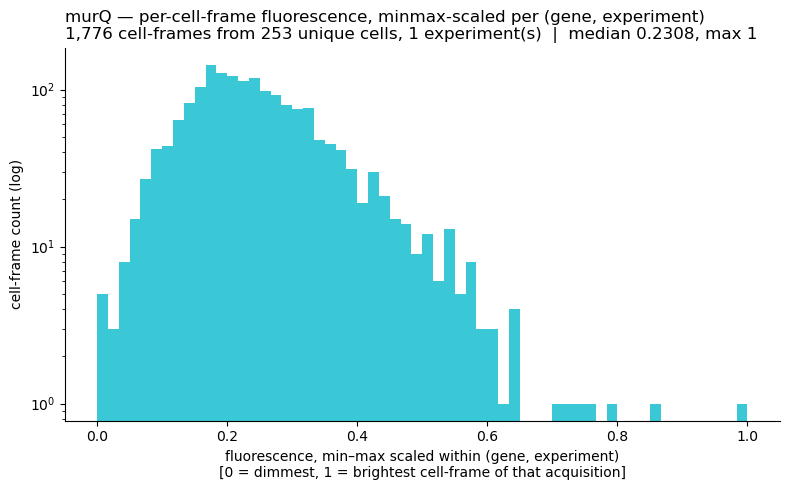

In [5]:
# Set 3 -- the same frame on LOG counts. On linear counts a 20-cell-frame tail beside a
# 3,000-cell-frame mode is a flat line, and that is exactly where the bursts are.
for _gene in sorted(clean['gene'].dropna().unique()):
    F.plot_fluor_histogram(clean, _gene, value_col=FLUOR, normalize='minmax',
                           count_scale='log', save=False)

---
# 2 — Every threshold, for every kymograph

`F.kymo_threshold_table` is the single source of truth for every line the figures draw. It
carries three families of threshold at **both** the kymograph and the `(gene, experiment)` scope,
and they answer different questions.

| family | column | what it is |
|---|---|---|
| **quantile** | `p95`, `p99` | the top 5% / 1% of that group. A *quantile*, not a test |
| **outlier** | `tukey_fence` = `Q3 + 1.5·IQR` | a real test: the flagged fraction depends on shape |
| **detector** | `local_bar`, `gene_bar` = `median + 4·s` | the shipped rule, `s = 1.4826·MAD` |

The MAD family is kept because it is the tie back to `bursts.md`: it reproduces the documented
**43%** gene-bar and **59%** local-bar trench coverage, and `local_bar` is taken from
`Bu.attach_kymograph_baselines(scope='kymograph')` rather than re-derived, so it is the
detector's own number.

The table is sorted by `frac_above_own_tukey`, **not** by a p95 count — a p95 count is `0.05·n`
and would sort the table by trench size.

In [6]:
thr = F.kymo_threshold_table(clean, k=K, scale_floor_frac=SCALE_FLOOR_FRAC, fluor_col=FLUOR)
print(f'{len(thr)} kymographs, {len(thr.columns)} columns\n')

_g = thr.groupby('gene')
summary = pd.DataFrame({
    'n_kymo': _g.size(),
    'n_cell_frames': _g['n_cell_frames'].sum(),
    'med_frac_tukey': _g['frac_above_own_tukey'].median().round(4),
    'tot_tukey': _g['n_above_own_tukey'].sum(),
    'tot_tukey_far': _g['n_above_own_tukey_far'].sum(),
    'max_p99_p50': _g['p99_over_p50'].max().round(2),
    'above_gene_p95': _g['n_above_gene_p95'].sum(),
    'above_gene_bar': _g['n_above_gene_bar'].sum(),
    'above_local_bar': _g['n_above_local_bar'].sum(),
    'elig_gene_%': (100 * _g['eligible_gene'].mean()).round(0),
    'elig_local_%': (100 * _g['eligible_local'].mean()).round(0),
})
summary['CTL'] = ['<<<' if g in ('hupA', 'mazF', 'chpS') else '' for g in summary.index]
print(summary.sort_values('med_frac_tukey', ascending=False).to_string())

print(f"\ncoverage: {100 * thr['eligible_gene'].mean():.0f}% of kymographs can reach their "
      f"GENE bar, {100 * thr['eligible_local'].mean():.0f}% their OWN bar")
print('bursts.md §7/§8 quote 43% and 59% -- these reproduce it exactly.')

# p95 is a quantile: assert it, so the claim in the header cannot silently rot.
_fr = thr['frac_above_own_p95']
print(f'\nfraction above own p95: min {_fr.min():.4f}, median {_fr.median():.4f}, '
      f'max {_fr.max():.4f}  -- pinned at 5% by construction')
assert 0.04 < _fr.min() and _fr.max() < 0.10

255 kymographs, 45 columns

      n_kymo  n_cell_frames  med_frac_tukey  tot_tukey  tot_tukey_far  max_p99_p50  above_gene_p95  above_gene_bar  above_local_bar  elig_gene_%  elig_local_%  CTL
gene                                                                                                                                                               
lacZ      23          11904          0.0569        690            240         5.86             596             336              419         87.0         100.0     
gldA      19           5866          0.0364        213             24         3.76             295              20               66         32.0          68.0     
gfcE      37          11484          0.0345        406             76         3.51             576             114              177         54.0          68.0     
alkA      23           6974          0.0286        215             41         3.98             351              53               95         52.0        

### What that table says

**Tukey's fence discriminates; the MAD bar and p95 do not.** Read `med_frac_tukey`: the three
constitutive controls land **6th, 7th and 8th of 10**, with lacZ top and baeS bottom. That
reproduces the shape of the shipped per-gene ranking (`bursts.md` §10) using **no peak detection,
no prominence and no gene-scoped baseline** — two routes with no shared machinery agreeing, which
is the evidence standard `bursts.md` sets.

**`max_p99_p50` separates the controls outright.** All five bursty genes reach ≥ 3.51; all three
controls stop at ≤ 2.85. That is a unit-free band, `(2.85, 3.51]`, directly analogous to v5's
fold band of `(3.10, 3.60]` — and it needs no denominator floor, because raw
`intensity_mean_fluor` is strictly positive (min 0.346, every per-kymograph median ≥ 1.50) where
v6's `fold_left` had to floor at `0.5·m` after an unfloored `left_base` of 0.006 scored 30×.

**But per trench the controls are not at zero** — hupA and mazF still carry Tukey-flagged
cell-frames. The control holds in the per-gene *ranking*, not trench by trench, which is the
difference between this and an event definition.

---
# 3 — One selection at a time

`F.plot_fluor_histogram_scoped(clean, experiment=, gene=, fov=, trench_id=)` — every field
optional, `None` meaning no filter, so one entry point covers a whole gene down to a single
kymograph.

**One histogram, the selected trench alone, on a linear count axis.** The population view is
§1's job and there is no reason to repeat it here. Both reference lines are still drawn without
it, and that is the point: the **gene p95** (red, dashed) is a vertical mark showing where that
gene's top-5% cut falls across this trench's own distribution, and the **own p95** (purple,
dash-dot) is this trench's. A dim trench legitimately has 0 cell-frames past the red line.

Pass `backdrop='gene_experiment'` to draw the population behind it. Measured over all 255
trenches it is **1.0×–227×** larger, median **15×**, so `layout` defaults to `'stacked'` whenever
a backdrop is asked for: two panels, two honest count axes. `twin_y=True` overlays them on a
second y-axis instead — compact, but a dual-axis chart is the most misread chart form there is,
so it is off by default.

**Linear counts read the bulk; log counts read the tail.** 3a below shows both, because that is
where the difference bites: a burst is a handful of cell-frames beside a mode of ~90, so on a
linear axis the tail is nearly flat — and the tail is the burst. Neither scale is wrong; they
answer different questions.

Every case below has a **known answer**, so the figures are checked rather than admired. Pass
`thresholds=thr` to reuse the table instead of recomputing it per call.

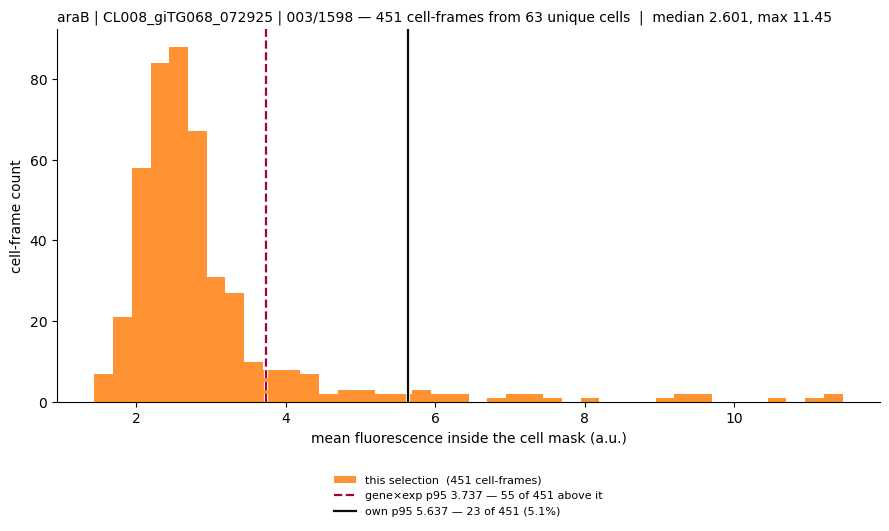

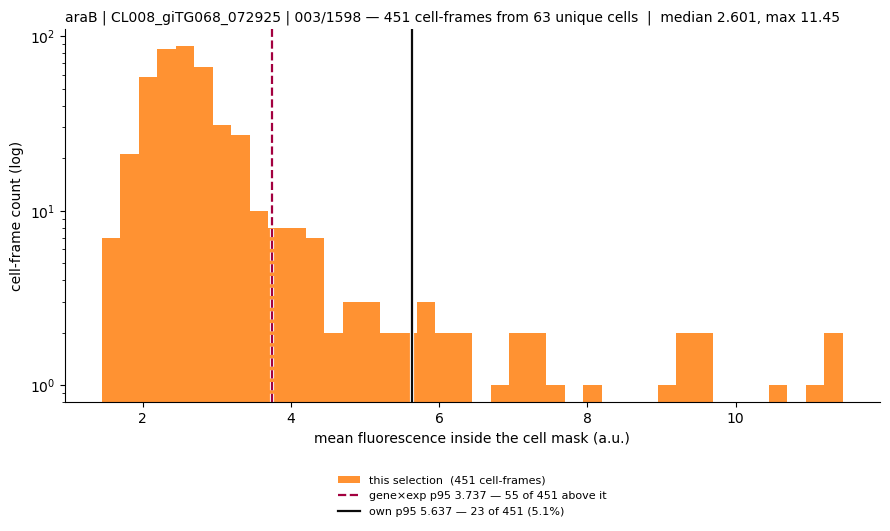

In [7]:
# --- 3a. The canonical clean burst: araB CL008 003/1598, peak at time_frame 39 -----------
# bursts.md's worked example: the cell climbs to 11.45 a.u. against a trench median of 2.60,
# then decays by DILUTION as it grows -- F*area is flat to within 4% over 16 frames.
# Clears everything, and the flagged run (frames 37-66) is that whole single episode.
# Both count scales, because this is the trench where the choice matters most: the mode holds
# ~90 cell-frames and the whole burst is the 1-3 cell-frames per bin out at 6-11.5 a.u.
#
# NOTE the fence flags 44 cell-frames here over 33 distinct frames -- 37-66, a 15-frame gap,
# then 81/86/87 (track 50, real cells). Not one contiguous run; see the header.
for _cs in ('linear', 'log'):
    F.plot_fluor_histogram_scoped(clean, experiment='CL008_giTG068_072925', gene='araB',
                                  fov='003', trench_id='1598', value_col=FLUOR,
                                  count_scale=_cs, thresholds=thr)

median 6.90 | p95 12.60 | tukey 14.89 | MAD bar 16.63 | max 15.72
above MAD bars: gene 0, own 0
above tukey   : 2 cell-frames over 2 distinct time_frames [31, 39]
the documented v6 peak is time_frame 31.


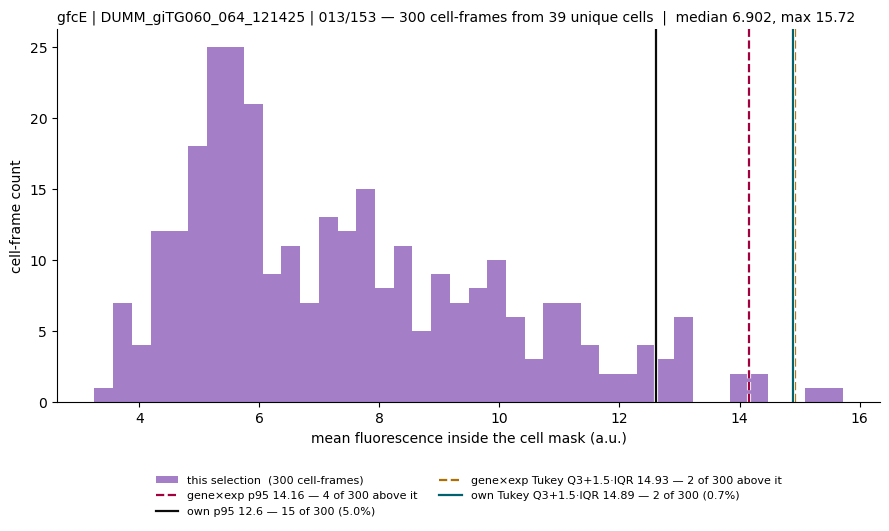

In [8]:
# --- 3b. gfcE 013/153 -- v6's worked example. THE case that changed with the fence --------
# Under a height bar this trench is invisible: its brightest cell-frame is below BOTH its gene
# bar and its own local bar (printed below), so round 1 had to show it as a negative control.
# Its Tukey fence sits at 14.89 and flags exactly TWO cell-frames of 300 -- frames 31 and 39 --
# and frame 31 is the documented v6 peak. The fence is not magic: 1.5*IQR above Q3 is 7.99
# above the median where 4*s is 9.73, so it is simply a lower bar on a trench whose bulk is
# tight. What matters is that it is lower in a SHAPE-aware way and still ranks the controls low.
_f = F.plot_fluor_histogram_scoped(clean, experiment='DUMM_giTG060_064_121425', gene='gfcE',
                                   fov='013', trench_id='153', value_col=FLUOR,
                                   bars=('p95', 'tukey'), thresholds=thr)
_r = F.select_scope(thr, experiment='DUMM_giTG060_064_121425', fov='013',
                    trench_id='153').iloc[0]
_s = F.select_trench(clean, 'DUMM_giTG060_064_121425', '013', '153')
print(f'median {_r.fluor_med:.2f} | p95 {_r.p95:.2f} | tukey {_r.tukey_fence:.2f} | '
      f'MAD bar {_r.local_bar:.2f} | max {_r.fluor_max:.2f}')
print(f'above MAD bars: gene {int(_r.n_above_gene_bar)}, own {int(_r.n_above_local_bar)}')
_ft = sorted(int(x) for x in _s.loc[_s[FLUOR] > _r.tukey_fence, 'time_frame'].unique())
print(f'above tukey   : {int(_r.n_above_own_tukey)} cell-frames over {len(_ft)} distinct '
      f'time_frames {_ft}')
print('the documented v6 peak is time_frame 31.')

above MAD bars: gene 0, own 0
above tukey   : 4 cell-frames over 4 distinct time_frames [9, 10, 11, 30]
the documented v5 peak is time_frame 9.


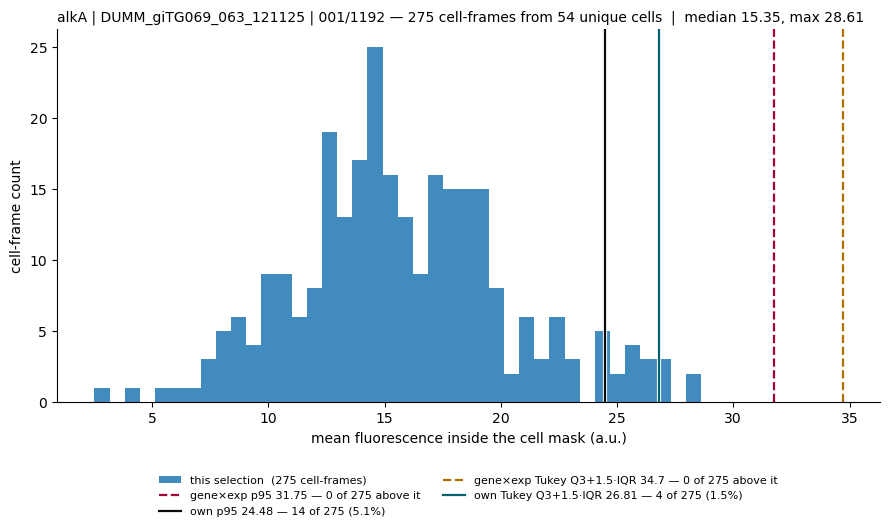

In [9]:
# --- 3c. alkA 001/1192 -- v5's motivating case, also now reached -------------------------
# A 3.5x rise and the brightest cell-frame in its whole trench, yet only 1.91 MAD-scales above
# its gene median -- and its own local bar is above its trench max too, so no height rule at
# either scope produced a single candidate. The fence flags 4 of 275, including frame 9 (the
# documented peak) plus 10 and 11, which are its decay.
_r = F.select_scope(thr, experiment='DUMM_giTG069_063_121125', fov='001',
                    trench_id='1192').iloc[0]
_s = F.select_trench(clean, 'DUMM_giTG069_063_121125', '001', '1192')
F.plot_fluor_histogram_scoped(clean, experiment='DUMM_giTG069_063_121125', gene='alkA',
                              fov='001', trench_id='1192', value_col=FLUOR,
                              bars=('p95', 'tukey'), thresholds=thr)
print(f'above MAD bars: gene {int(_r.n_above_gene_bar)}, own {int(_r.n_above_local_bar)}')
_ft = sorted(int(x) for x in _s.loc[_s[FLUOR] > _r.tukey_fence, 'time_frame'].unique())
print(f'above tukey   : {int(_r.n_above_own_tukey)} cell-frames over {len(_ft)} distinct '
      f'time_frames {_ft}')
print('the documented v5 peak is time_frame 9.')

scale_ratio 1.33 -> gene bar 49.14, own bar 61.91  (own is STRICTER)


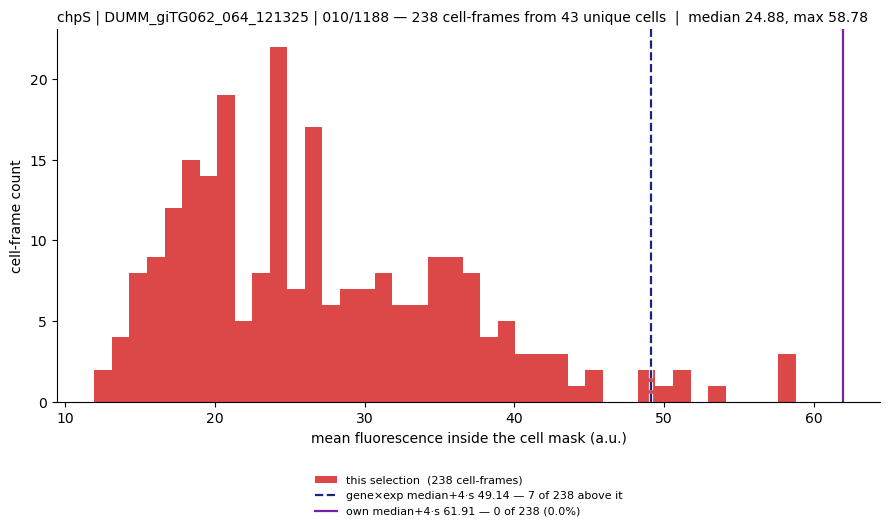

In [10]:
# --- 3d. chpS 010/1188 -- the case a local baseline LOSES --------------------------------
# This trench's own MAD is LARGER than its gene's (scale_ratio 1.33), so its local MAD bar sits
# ABOVE its gene bar and the same event drops from 5.38 to 3.66 MAD-scales. First of the four
# reasons v5local was not shipped. Drawn with bars='mad' so the inversion is visible: the
# purple line is to the RIGHT of the red one.
F.plot_fluor_histogram_scoped(clean, experiment='DUMM_giTG062_064_121325', gene='chpS',
                              fov='010', trench_id='1188', value_col=FLUOR,
                              bars='mad', thresholds=thr)
_r = F.select_scope(thr, experiment='DUMM_giTG062_064_121325', fov='010',
                    trench_id='1188').iloc[0]
print(f'scale_ratio {_r.scale_ratio:.2f} -> gene bar {_r.gene_bar:.2f}, '
      f'own bar {_r.local_bar:.2f}  (own is STRICTER)')

hupA 005/648: n=204, tukey flags 4 (2.0%), p99/p50 2.27
mazF 006/327: n=143, tukey flags 6 (4.2%), p99/p50 1.76


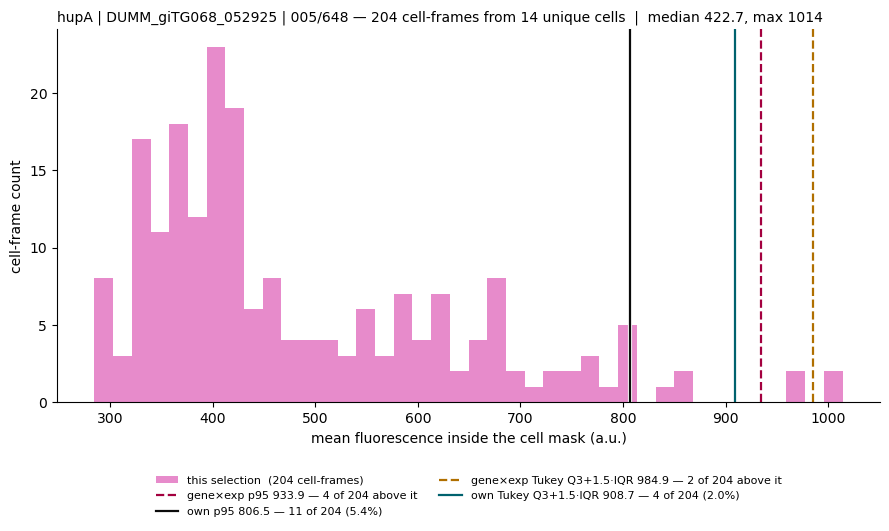

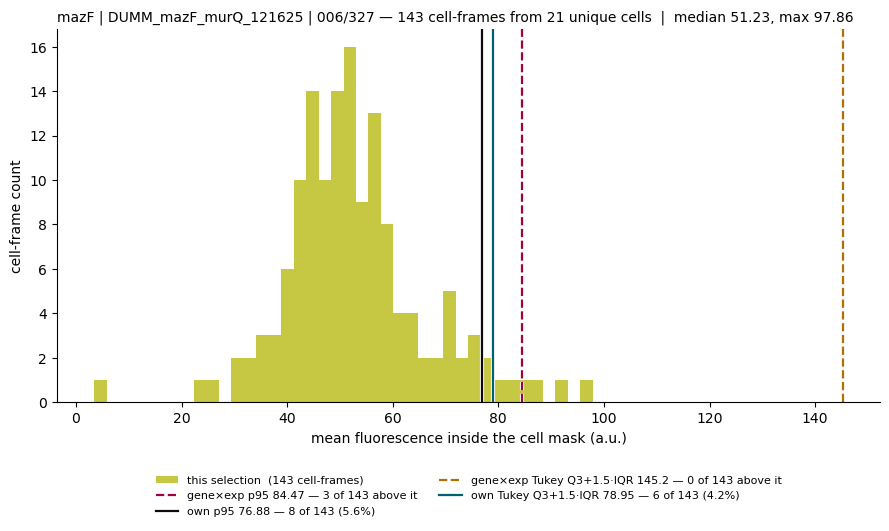

In [11]:
# --- 3e. The constitutive controls, where a wrong method shows itself --------------------
# Broad symmetric humps with no isolated right tail. Both still carry a few Tukey-flagged
# cell-frames -- the control holds in the per-gene RANKING (§2), not trench by trench -- and
# neither becomes an event under any definition, because both fail local-max + prominence.
for _e, _g, _f, _t in (('DUMM_giTG068_052925', 'hupA', '005', '648'),
                       ('DUMM_mazF_murQ_121625', 'mazF', '006', '327')):
    F.plot_fluor_histogram_scoped(clean, experiment=_e, gene=_g, fov=_f, trench_id=_t,
                                  value_col=FLUOR, bars=('p95', 'tukey'), thresholds=thr)
    _r = F.select_scope(thr, experiment=_e, fov=_f, trench_id=_t).iloc[0]
    print(f'{_g} {_f}/{_t}: n={int(_r.n_cell_frames)}, tukey flags '
          f'{int(_r.n_above_own_tukey)} ({_r.frac_above_own_tukey:.1%}), '
          f'p99/p50 {_r.p99_over_p50:.2f}')

NOTE: reference lines are drawn only for normalize='none' -- they are in mean fluorescence inside the cell mask (a.u.) and 'kymo_minmax' rescales the axis away from them.
max |raw_kymo_minmax - perms_kymo_minmax| = 4.44e-16


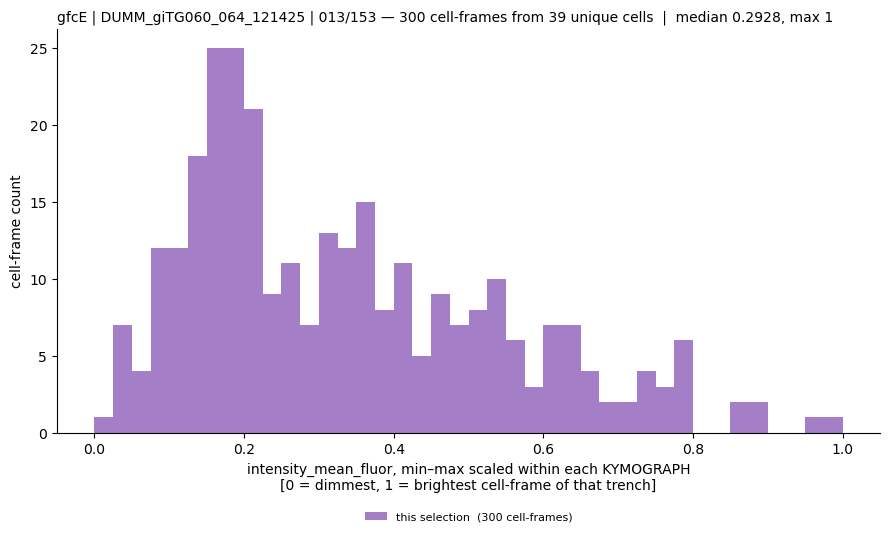

In [12]:
# --- 3f. The pre-computed per-kymograph min-max axis ------------------------------------
# `normalize='kymo_minmax'` reads the export's own `{value_col}_kymo_minmax` column -- a min-max
# within one kymograph, 292 groups, on disk for all 90,010 rows and until now consumed by
# nothing. 0 = this trench's dimmest cell-frame, 1 = its brightest.
#
# NOT the same quantity as normalize='minmax', which partitions by (gene, experiment) (~30
# groups). And note intensity_mean_fluor_kymo_minmax == fluor_per_ms_kymo_minmax exactly, for
# the same reason the whole notebook can drop the exposure division.
F.plot_fluor_histogram_scoped(clean, experiment='DUMM_giTG060_064_121425', gene='gfcE',
                              fov='013', trench_id='153', value_col=FLUOR,
                              normalize='kymo_minmax', thresholds=thr)
_a = clean['intensity_mean_fluor_kymo_minmax']; _b = clean['fluor_per_ms_kymo_minmax']
print(f'max |raw_kymo_minmax - perms_kymo_minmax| = {(_a - _b).abs().max():.2e}')

---
# 4 — The worklist

Every kymograph ranked by `frac_above_own_tukey` — the fraction of its cell-frames above its own
`Q3 + 1.5·IQR`. Shape-sensitive, so unlike a p95 count it is not simply `0.05·n`.

**How to read it, and how not to.** This is not an event count: flagged frames come in contiguous
runs (araB 003/1598 flags frames 37–66, one burst plus its dilution decay), so any count mixes
magnitude with duration. What the column is good for is *ordering* which kymographs to open in
the viewer.

Two columns qualify every row:

- **`headroom_gene_s` < 0** — the brightest cell-frame could never reach the gene bar, so this
  trench is structurally invisible to the shipped detector at any `k`. That is where this route
  adds something.
- **`scale_ratio` < 1** — the trench is quieter than its gene, so a local threshold is a genuine
  loosening rather than a tightening.

The constitutive genes stay in the table rather than being filtered out: they are the
falsification check.

In [13]:
WORK_COLS = ['gene', 'experiment_name', 'FOV', 'trench_id', 'n_cell_frames', 'n_cells',
             'n_above_own_tukey', 'frac_above_own_tukey', 'n_above_own_tukey_far',
             'n_above_gene_p95', 'p99_over_p50', 'scale_ratio', 'headroom_gene_s',
             'fluor_med', 'p95', 'tukey_fence', 'fluor_max']

work = thr[thr['n_above_own_tukey'] > 0].copy()
work['blind_to_gene_bar'] = work['headroom_gene_s'] < 0

print(f'{len(work)} of {len(thr)} kymographs flag at least one cell-frame; '
      f'{int(work.blind_to_gene_bar.sum())} of those could never reach their gene bar.\n')
print(work.head(25)[WORK_COLS].round(3).to_string(index=False))

220 of 255 kymographs flag at least one cell-frame; 113 of those could never reach their gene bar.

gene                   experiment_name FOV trench_id  n_cell_frames  n_cells  n_above_own_tukey  frac_above_own_tukey  n_above_own_tukey_far  n_above_gene_p95  p99_over_p50  scale_ratio  headroom_gene_s  fluor_med     p95  tukey_fence  fluor_max
gldA           DUMM_giTG069_063_121125 013       490             80       15                 11                 0.138                      8                 6         3.612        0.352           -0.351      7.554  22.092       12.154     29.322
araB         DUMM_CL008_giTG061_081225 017       970             22        6                  3                 0.136                      2                 7         2.264        1.044            5.668      3.332   7.018        4.982      7.671
gfcE           DUMM_giTG060_064_121425 020      1100             76       18                  9                 0.118                      2                 8    

In [14]:
# The leads that matter most: structurally invisible to the gene bar (headroom < 0) AND
# genuinely quieter than their gene (scale_ratio < 1). Nothing a gene-scoped height threshold
# could ever have found, at any k.
leads = work[work.blind_to_gene_bar & (work.scale_ratio < 1)]
print(f'{len(leads)} leads across {leads.gene.nunique()} genes\n')
_t = (leads.groupby('gene')
           .agg(n_kymo=('trench_id', 'size'), tukey_frames=('n_above_own_tukey', 'sum'),
                med_frac=('frac_above_own_tukey', 'median'),
                max_p99_p50=('p99_over_p50', 'max'))
           .sort_values('med_frac', ascending=False).round(3))
_t['CTL'] = ['<<<' if g in ('hupA', 'mazF', 'chpS') else '' for g in _t.index]
print(_t.to_string())
print()
print(leads.head(20)[WORK_COLS].round(3).to_string(index=False))

109 leads across 10 genes

      n_kymo  tukey_frames  med_frac  max_p99_p50  CTL
gene                                                  
lacZ       3            45     0.039        4.142     
gfcE      15           209     0.037        3.300     
gldA      12           103     0.036        3.612     
chpS       6            77     0.033        2.272  <<<
alkA       8            55     0.028        2.581     
mazF      11            54     0.023        2.026  <<<
murQ       4            12     0.021        1.968     
hupA       1             4     0.020        2.274  <<<
araB      22           112     0.017        2.519     
baeS      27           178     0.016        4.225     

gene                   experiment_name FOV trench_id  n_cell_frames  n_cells  n_above_own_tukey  frac_above_own_tukey  n_above_own_tukey_far  n_above_gene_p95  p99_over_p50  scale_ratio  headroom_gene_s  fluor_med     p95  tukey_fence  fluor_max
gldA           DUMM_giTG069_063_121125 013       490             8

In [15]:
# Falsification check: the controls must not dominate any ranking here.
_ctl = ('hupA', 'mazF', 'chpS')
print(f'control share of all Tukey-flagged cell-frames: '
      f'{100 * thr[thr.gene.isin(_ctl)].n_above_own_tukey.sum() / thr.n_above_own_tukey.sum():.1f}%'
      f'  from {100 * thr.gene.isin(_ctl).mean():.0f}% of kymographs')
print(f'controls in the top 25 of the worklist: '
      f'{int(work.head(25).gene.isin(_ctl).sum())} of 25')
print(f'controls in the leads table: {int(leads.gene.isin(_ctl).sum())} of {len(leads)}')

control share of all Tukey-flagged cell-frames: 9.4%  from 13% of kymographs
controls in the top 25 of the worklist: 0 of 25
controls in the leads table: 18 of 109


---
# 5 — Does the fence agree with the shipped detector?

§2 showed the Tukey ranking reproduces the *shape* of the per-gene burst ranking. This section
checks the two routes event by event, which is the stronger claim.

They share **no machinery**: v6 runs peak detection on a per-lineage-family max envelope against
a `(gene, experiment)` median and MAD, with a local-maximum test, MAD-prominence and two fold
routes. The fence is a quartile statistic on one trench's marginal distribution with time thrown
away. Where they agree, that is real evidence; where they disagree, it is a lead.

A v6 event counts as **corroborated** when the fence flags any cell-frame in the same trench
within ±`window` frames of it (`window = 5`, v6's own local-maximum half-width).

**One guard before reading the disagreements.** The fence flags at least one cell-frame in **220
of 255 trenches**, because it flags ~3% of almost any distribution (median
`frac_above_own_tukey` 0.026, pooled 2,618/81,799 = 0.032). So "the fence flags this
trench and v6 does not" is close to vacuous on its own — the information is in the *fraction*
and in the *ranking*, not in the binary. Weigh a fence-only trench by `frac_above_own_tukey` and
`max_p99_p50`, and note that the constitutive genes appear in that list too.

In [16]:
# v6's 156 events. Detection is re-run rather than read from CSV so the comparison is against
# the definition, not against a possibly stale export.
v6, _ = Bu.run_burst_detection_any(clean, Bu.BURST_DEF_V6)
WINDOW = Bu.BURST_DEF_V6['window']
print(f'v6: {len(v6)} events, {len(v6[F.KYMO_KEY].drop_duplicates())} trenches')
assert len(v6) == 156, len(v6)

# Tukey-flagged cell-frames. Broadcast the per-trench fence back onto rows with the same
# MultiIndex idiom attach_kymograph_baselines uses (bursts.py:725) -- set_index() on a list of
# tuples would read them as COLUMN NAMES, not values.
_fence = thr.set_index(F.KYMO_KEY)['tukey_fence']
assert _fence.index.is_unique, 'a trench should belong to exactly one gene'
_idx = pd.MultiIndex.from_arrays([clean[c] for c in F.KYMO_KEY])
flag = clean[clean[FLUOR].to_numpy() > _fence.reindex(_idx).to_numpy()]
print(f'fence: {len(flag):,} flagged cell-frames in '
      f'{len(flag[F.KYMO_KEY].drop_duplicates())} trenches')

_by_trench = {k: set(g['time_frame'].astype(int))
              for k, g in flag.groupby(F.KYMO_KEY, observed=True)}

def corroborated(row):
    fr = _by_trench.get((row.experiment_name, row.FOV, row.trench_id), set())
    return any(abs(f - int(row.time_frame)) <= WINDOW for f in fr)

v6 = v6.copy()
v6['fence_agrees'] = [corroborated(r) for r in v6.itertuples()]
n_ok = int(v6.fence_agrees.sum())
print(f'\nv6 events corroborated by the fence: {n_ok} of {len(v6)} '
      f'({100 * n_ok / len(v6):.0f}%)')
print('\nby route:')
print(v6.groupby('route')['fence_agrees'].agg(n='size', agrees='sum').to_string())
print('\nby gene:')
print(v6.groupby('gene')['fence_agrees'].agg(n='size', agrees='sum')
        .sort_values('n', ascending=False).to_string())

v6: 156 events, 101 trenches
fence: 2,618 flagged cell-frames in 220 trenches

v6 events corroborated by the fence: 144 of 156 (92%)

by route:
            n  agrees
route                
absolute   99      97
fold       19      18
fold_left  38      29

by gene:
       n  agrees
gene            
lacZ  38      38
gfcE  28      25
gldA  24      22
alkA  23      20
araB  22      22
baeS  14      10
chpS   5       5
murQ   2       2


In [17]:
# The disagreements, both directions.
print('=== v6 events the fence does NOT flag ===')
_miss = v6[~v6.fence_agrees]
print(f'{len(_miss)} events, {_miss.gene.nunique()} genes')
if len(_miss):
    print(_miss.groupby('gene').size().sort_values(ascending=False).to_string())
    print()
    # `fluor` here is v6's own column, BURST_DEF_V6['fluor_col'] == 'fluor_per_ms' --
    # a.u./MS, not the raw a.u. every other number in this notebook is in. Renamed in the
    # printout so it cannot be read against a raw median.
    print(_miss[['gene', 'experiment_name', 'FOV', 'trench_id', 'time_frame', 'route',
                 'fluor']].rename(columns={'fluor': 'fluor_per_ms'})
          .head(15).round(4).to_string(index=False))

print('\n=== trenches the fence flags where v6 has no event ===')
_v6_tr = set(tuple(r) for r in v6[F.KYMO_KEY].to_numpy())
fence_only = thr[(thr.n_above_own_tukey > 0)
                 & ~thr.apply(lambda r: (r.experiment_name, r.FOV, r.trench_id) in _v6_tr,
                              axis=1)]
print(f'{len(fence_only)} trenches')
_t = (fence_only.groupby('gene')
      .agg(n_kymo=('trench_id', 'size'), tukey_frames=('n_above_own_tukey', 'sum'),
           med_frac=('frac_above_own_tukey', 'median'), max_p99_p50=('p99_over_p50', 'max'))
      .sort_values('med_frac', ascending=False).round(3))
_t['CTL'] = ['<<<' if g in ('hupA', 'mazF', 'chpS') else '' for g in _t.index]
print(_t.to_string())

=== v6 events the fence does NOT flag ===
12 events, 4 genes
gene
baeS    4
alkA    3
gfcE    3
gldA    2

gene             experiment_name FOV trench_id  time_frame     route  fluor_per_ms
gfcE     DUMM_giTG060_064_121425 020       874          10  absolute        0.1455
gfcE DUMM_giTG064_Glucose_022625 001      1521           3 fold_left        0.0503
gfcE DUMM_giTG064_Glucose_022625 015      1508          45 fold_left        0.0439
baeS     DUMM_giTG066_063_120925 007       721          15 fold_left        0.2425
alkA     DUMM_giTG068_063_061725 006      1015          87 fold_left        0.0939
alkA     DUMM_giTG069_063_121125 008       744           8  absolute        0.3036
alkA     DUMM_giTG069_063_121125 008       744          15 fold_left        0.2737
gldA     DUMM_giTG069_063_121125 013      1640          37      fold        0.1061
gldA     DUMM_giTG069_063_121125 025      2052          31 fold_left        0.1414
baeS    DUMM_gitg068_baeS_100225 013       499          66 fold

In [18]:
# The per-gene ranking, side by side with bursts.md §10's v6 counts.
_uniq = clean.drop_duplicates(F.CELL_KEY).groupby('gene').size()
cmp = pd.DataFrame({
    'v6_events': v6.groupby('gene').size(),
    'tukey_med_frac': thr.groupby('gene')['frac_above_own_tukey'].median(),
    'max_p99_p50': thr.groupby('gene')['p99_over_p50'].max(),
    'n_cells': _uniq,
}).fillna(0)
cmp['v6_per_100_cells'] = (100 * cmp.v6_events / cmp.n_cells)
# `.astype(int)` would truncate a tied rank: hupA and mazF both sit at 9.5 (both zero events),
# printing two 9s and no 10 in a ten-gene table. Keep the fractional rank.
cmp['rank_v6'] = cmp.v6_per_100_cells.rank(ascending=False)
cmp['rank_tukey'] = cmp.tukey_med_frac.rank(ascending=False)
cmp['CTL'] = ['<<<' if g in ('hupA', 'mazF', 'chpS') else '' for g in cmp.index]
print(cmp.round(3).sort_values('rank_tukey').to_string())
print(f'\nSpearman rank correlation between the two rankings: '
      f'{cmp.v6_per_100_cells.corr(cmp.tukey_med_frac, method="spearman"):.3f}')
print('\nbursts.md §10 v6 counts: lacZ 38, gfcE 28, gldA 24, alkA 23, araB 22, baeS 14, '
      'chpS 5, murQ 2, hupA 0, mazF 0')

      v6_events  tukey_med_frac  max_p99_p50  n_cells  v6_per_100_cells  rank_v6  rank_tukey  CTL
gene                                                                                             
lacZ       38.0           0.057        5.863     1462             2.599      2.0         1.0     
gldA       24.0           0.036        3.764      777             3.089      1.0         2.0     
gfcE       28.0           0.034        3.514     1525             1.836      4.0         3.0     
alkA       23.0           0.029        3.978     1012             2.273      3.0         4.0     
araB       22.0           0.024        3.686     2230             0.987      5.0         5.0     
chpS        5.0           0.024        2.510      777             0.644      7.0         6.0  <<<
mazF        0.0           0.020        2.854      520             0.000      9.5         7.0  <<<
hupA        0.0           0.019        2.274      184             0.000      9.5         8.0  <<<
murQ        2.0     

---
# 6 — Burst v7: the fence as a shipped route

§5 showed the fence corroborates 92% of v6 from no shared machinery. This section promotes it to
a **fourth detection route**, OR'd in alongside `absolute` / `fold` / `fold_left`, so
`mmtrack.bursts.BURST_DEF_V7` is v6 plus "clear your own trench's `Q3 + κ·IQR`".

That is a different *kind* of criterion from everything before it. v1–v6 are all
location-and-scale statements about the (gene, experiment) median — a height, or a ratio against
a peak's own flanks — and `bursts.md` §8 records four attempts at re-scoping that median, none
shipped. A quartile fence is a statement about the **shape** of one trench's own distribution.

**κ = 4.0, not the textbook 1.5.** The sweep below is the reason, and it says something no
earlier route had to admit: there is no κ at which this route both adds events and leaves the
constitutive control at zero. The control-clean band is [4.4, 4.8] and buys 4 events; 4.0 buys 8
for exactly one hupA event. 4.0 is shipped on the argument that a constitutive gene can still
burst and a hard zero is this project's convention rather than a law — but the cost is named, not
hidden, and `tukey_iqr_k=4.4` is the strict variant.

Know what that one hupA event is: 012/1165 frame 81, F = 7.73 against a gene bar of 6.17.
**Bright but not prominent** — Denver, in `bursts.md` §4's terms. It clears the height bar and
fails prominence, and a marginal distribution cannot tell the difference because it has thrown
the time axis away. That is this route's standing limitation.

In [19]:
FC = Bu.BURST_DEF_V7['fluor_col']      # 'fluor_per_ms' -- the DETECTOR's column, not FLUOR
print(f'detector runs on {FC!r}; the fence must be computed on the same column.')
print('raw and per-ms fences give identical verdicts but differ by 150-500x, so mixing them '
      'is wrong\nby up to 500x and raises nothing.\n')

_v6, _ = Bu.run_burst_detection_any(clean, Bu.BURST_DEF_V6)
_K6 = set(zip(_v6.experiment_name, _v6.FOV, _v6.trench_id.astype(str),
              _v6.time_frame.astype(int), _v6.track_id.astype(int)))
_PER6 = _v6.groupby('gene').size()
# The three trenches whose answer is known, asserted at every setting since v4.
REG = {('CL008_giTG068_072925', '003', '1598'): 1,
       ('CL008_giTG068_072925', '007', '821'): 1,
       ('DUMM_giTG059_060_061125', '008', '1488'): 4}

_rows = []
for _k in (1.5, 2.5, 3.0, 3.4, 4.0, 4.4, 4.8, 5.0):
    _d = Bu.attach_kymograph_fence(clean, fluor_col=FC, iqr_k=_k)
    _got, _ = Bu.run_burst_detection_any(_d, {**Bu.BURST_DEF_V7, 'tukey_iqr_k': _k},
                                         fence_col='_tukey_fence')
    _K7 = set(zip(_got.experiment_name, _got.FOV, _got.trench_id.astype(str),
                  _got.time_frame.astype(int), _got.track_id.astype(int)))
    _per = _got.groupby('gene').size()
    _kt = [tuple(x) for x in _got[F.KYMO_KEY].to_numpy()]
    _rows.append({'iqr_k': _k, 'events': len(_got), 'added': len(_K7 - _K6),
                  'lost': len(_K6 - _K7), 'superset': _K7 >= _K6,
                  'hupA': int(_per.get('hupA', 0)), 'mazF': int(_per.get('mazF', 0)),
                  'chpS': int(_per.get('chpS', 0)),
                  'regression': 'ok' if all(_kt.count(k) == w for k, w in REG.items())
                                else 'BROKEN'})
_sw = pd.DataFrame(_rows)
_sw['control'] = np.where((_sw.hupA == 0) & (_sw.mazF == 0), 'pass', 'fails')
print(_sw.to_string(index=False))
print(f'\nv6 = {len(_v6)} events.  v6 per gene: {dict(_PER6)}')
print('every row is a strict superset of v6 with zero losses -- the route only ever ADDS.')

detector runs on 'fluor_per_ms'; the fence must be computed on the same column.
raw and per-ms fences give identical verdicts but differ by 150-500x, so mixing them is wrong
by up to 500x and raises nothing.



 iqr_k  events  added  lost  superset  hupA  mazF  chpS regression control
   1.5     523    367     0      True     5    16    43     BROKEN   fails
   2.5     247     91     0      True     2     3     9     BROKEN   fails
   3.0     196     40     0      True     2     2     7     BROKEN   fails
   3.4     175     19     0      True     2     1     6         ok   fails
   4.0     164      8     0      True     1     0     5         ok   fails
   4.4     160      4     0      True     0     0     5         ok    pass
   4.8     159      3     0      True     0     0     5         ok    pass
   5.0     156      0     0      True     0     0     5         ok    pass

v6 = 156 events.  v6 per gene: {'alkA': np.int64(23), 'araB': np.int64(22), 'baeS': np.int64(14), 'chpS': np.int64(5), 'gfcE': np.int64(28), 'gldA': np.int64(24), 'lacZ': np.int64(38), 'murQ': np.int64(2)}
every row is a strict superset of v6 with zero losses -- the route only ever ADDS.


In [20]:
# The shipped setting, and the regression gate it has to pass.
_d7 = Bu.attach_kymograph_fence(clean, fluor_col=FC,
                                iqr_k=Bu.BURST_DEF_V7['tukey_iqr_k'])
v7, _ = Bu.run_burst_detection_any(_d7, Bu.BURST_DEF_V7, fence_col='_tukey_fence')
_K7 = set(zip(v7.experiment_name, v7.FOV, v7.trench_id.astype(str),
              v7.time_frame.astype(int), v7.track_id.astype(int)))

# v1-v6 must be bit-identical: the route is additive, not a re-tune.
_older = {}
for _v in ('v1', 'v2', 'v3', 'v4', 'v5', 'v6'):
    _b, _ = Bu.run_burst_detection_any(clean, Bu.BURST_DEFS[_v])
    _older[_v] = len(_b)
assert _older == {'v1': 73, 'v2': 89, 'v3': 89, 'v4': 99, 'v5': 118, 'v6': 156}, _older
print(f'v1-v6 unchanged: {_older}')

assert _K7 >= _K6, 'v7 must be a strict superset of v6'
print(f'v7 = {len(v7)} events, superset of v6, +{len(_K7 - _K6)} added, '
      f'{len(_K6 - _K7)} lost')

# v7 must not RELABEL what v6 found -- setdefault order + ROUTE_RANK['tukey']=3 guarantee it.
for _e, _f, _t, _fr, _want in (('DUMM_giTG060_064_121425', '013', '153', 31, 'fold_left'),
                               ('DUMM_giTG069_063_121125', '001', '1192', 9, 'fold')):
    _m = v7[(v7.experiment_name == _e) & (v7.FOV == _f) & (v7.trench_id == _t)
            & (v7.time_frame == _fr)]
    assert len(_m) == 1 and _m.route.iloc[0] == _want, (_e, _f, _t, _fr, _m.route.tolist())
    print(f'  {_f}/{_t} frame {_fr}: route={_want!r} preserved')

print(f'\nby route:\n{v7.route.value_counts().to_string()}')
print(f'\nthe {int((v7.route == "tukey").sum())} events the fence adds:')
print(v7[v7.route == 'tukey'][['gene', 'experiment_name', 'FOV', 'trench_id', 'time_frame',
                               'track_id', 'fluor', 'threshold']]
      .round(4).to_string(index=False))
_ctl = v7[(v7.route == 'tukey') & v7.gene.isin(['hupA', 'mazF', 'chpS'])]
print(f'\nof those, constitutive-gene events: {len(_ctl)} '
      f'({", ".join(_ctl.gene) if len(_ctl) else "none"})')
print('a fence cannot see a rise, so judge any tukey-only outline by eye in the viewer.')

v1-v6 unchanged: {'v1': 73, 'v2': 89, 'v3': 89, 'v4': 99, 'v5': 118, 'v6': 156}
v7 = 164 events, superset of v6, +8 added, 0 lost
  013/153 frame 31: route='fold_left' preserved
  001/1192 frame 9: route='fold' preserved

by route:
route
absolute     99
fold_left    38
fold         19
tukey         8

the 8 events the fence adds:
gene             experiment_name FOV trench_id  time_frame  track_id  fluor  threshold
araB           DUMM_CL008_080825 007      1936          40        30 0.0332     0.0378
araB           DUMM_CL008_080825 007      2087           3         5 0.0393     0.0378
araB   DUMM_CL008_giTG061_081225 017       970           4         6 0.0511     0.0311
lacZ  DUMM_giTG059_068_SC_093025 020       665          44        35 0.0492     0.0370
gfcE DUMM_giTG064_Glucose_022625 001       314          53        29 0.0276     0.0527
hupA     DUMM_giTG068_063_061725 012      1165          81        77 7.7326     6.1741
gldA     DUMM_giTG069_063_121125 013       490           1 

### The export and the viewer

`data/bursts_viewer_v10_090926.csv` carries v3/v4/v5/**v6**/**v7**/v5local, written by
`Bu.build_burst_csv` with the gene-scoped definitions first so shared rows report the gene bar
and only v5local's rows carry a per-trench `threshold` (`baseline_scope` says which).

The viewer layer is **yellow**, and adding it took six edits, not the three its own comment
claimed — `BURST_VERSIONS`, `BURST_COLORS`, the checkbox HTML, the `layers` JS array, and the
`--burst-csv` help text. The checkbox must exist before the `layers` entry: the toggle JS calls
`getElementById` with no null guard, so a `layers` entry without its checkbox throws and aborts
the whole script, leaving *every* layer uninitialised.

```
python generate_kymograph_viewer.py     --burst-csv data/bursts_viewer_v10_090926.csv     --output data/kymograph_viewer_bursts_090926c.html
```

**Yellow without cyan is one of the 8 events v7 adds.** Check those by eye before trusting one —
that is the whole reason the layer exists.

### The rate: v7 per cell cycle

**Bursts per cell cycle = episodes ÷ observed divisions**, so it reads as the chance of seeing a
burst per generation — the form worth comparing across genes that differ 10× in how long they
were imaged. `data/divisions_082026.csv` is one row per observed division and carries its own
`has_jump`, so this needs no pair table and the notebook stays pair-free.

Two figures. The single-definition bars are `plot_bursts_per_cell_cycle(version='v7')`, unchanged
machinery. The **grouped** plot is new — `plot_burst_rate_comparison` — because a definition
change is a statement about a *difference*, and a single-version bar chart cannot show one.
Colour there encodes the **definition**, not the gene, since gene is on the x-axis.

**Every definition is a superset of the last, so the bars can only rise.** Whether a rise means
anything is entirely whether the Poisson intervals separate, and between adjacent definitions on
this dataset they never do. Read the whiskers, not the bar tops.

In [21]:
divisions = pd.read_csv(f'{REPO_ROOT}/data/divisions_082026.csv', dtype=F.READ_DTYPES)
divisions['FOV'] = divisions['FOV'].str.zfill(3)
print(f'divisions: {len(divisions):,} events '
      f"({int((~divisions.has_jump).sum()):,} with no jump in the parent's lifetime)")

# The shipped union export, and a check that it agrees with what §6 just detected.
BURSTS_CSV = f'{REPO_ROOT}/data/bursts_090526.csv'
burst_union = F.load_bursts(BURSTS_CSV, cells=clean, version=None)


def _kset(d):
    return set(zip(d.experiment_name, d.FOV, d.trench_id.astype(str),
                   d.time_frame.astype(int), d.track_id.astype(int)))


assert _kset(burst_union[burst_union.burst_v7]) == _K7, \
    'the export disagrees with detection for v7'
assert _kset(burst_union[burst_union.burst_v6]) == _K6, \
    'the export disagrees with detection for v6'
print('export agrees with detection for v6 and v7.')
print(f'union: {len(burst_union)} rows | '
      + ' | '.join(f'{v}={int(burst_union[f"burst_{v}"].sum())}'
                   for v in ('v3', 'v4', 'v5', 'v6', 'v7', 'v5local')))

divisions: 5,279 events (4,890 with no jump in the parent's lifetime)
export agrees with detection for v6 and v7.
union: 231 rows | v3=89 | v4=99 | v5=118 | v6=156 | v7=164 | v5local=181


bursts per cell cycle [v7]

       n_bursts  n_divisions  per_cell_cycle   ci_lo   ci_hi  constitutive def_version
gene                                                                                  
gldA         25          344          0.0727  0.0470  0.1073         False          v7
lacZ         39          688          0.0567  0.0403  0.0775         False          v7
alkA         23          467          0.0493  0.0312  0.0739         False          v7
gfcE         29          701          0.0414  0.0277  0.0594         False          v7
murQ          3          108          0.0278  0.0057  0.0812         False          v7
araB         25         1033          0.0242  0.0157  0.0357         False          v7
chpS          5          356          0.0140  0.0046  0.0328          True          v7
hupA          1           88          0.0114  0.0003  0.0633          True          v7
baeS         14         1255          0.0112  0.0061  0.0187         False          v7
mazF          0

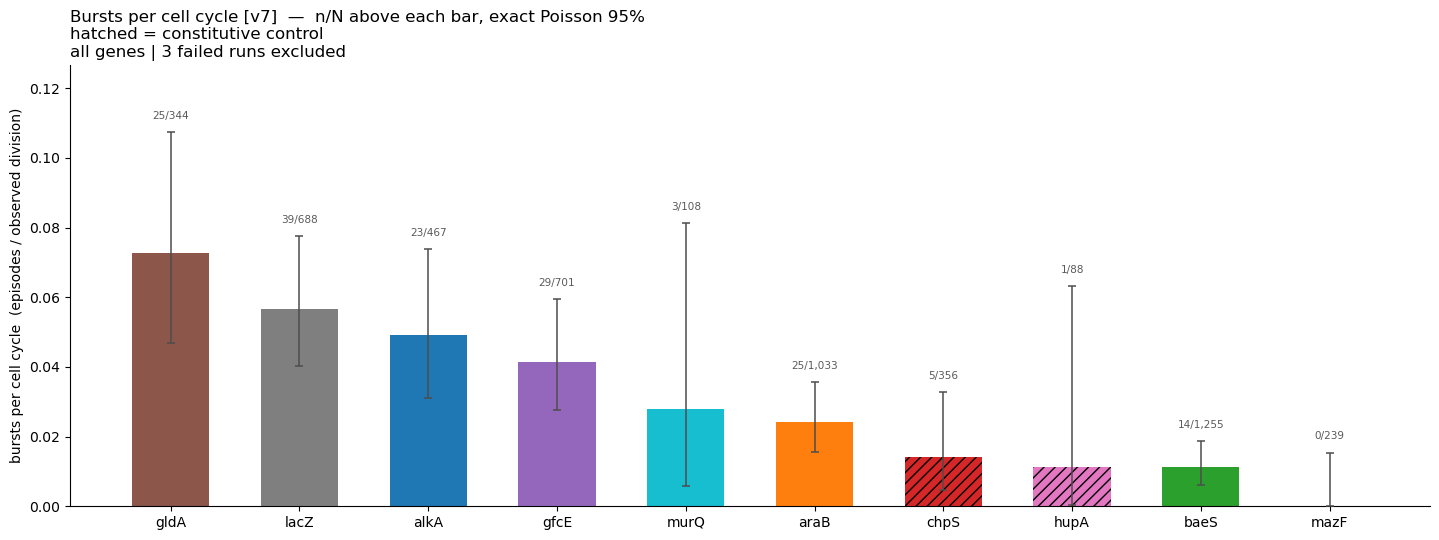

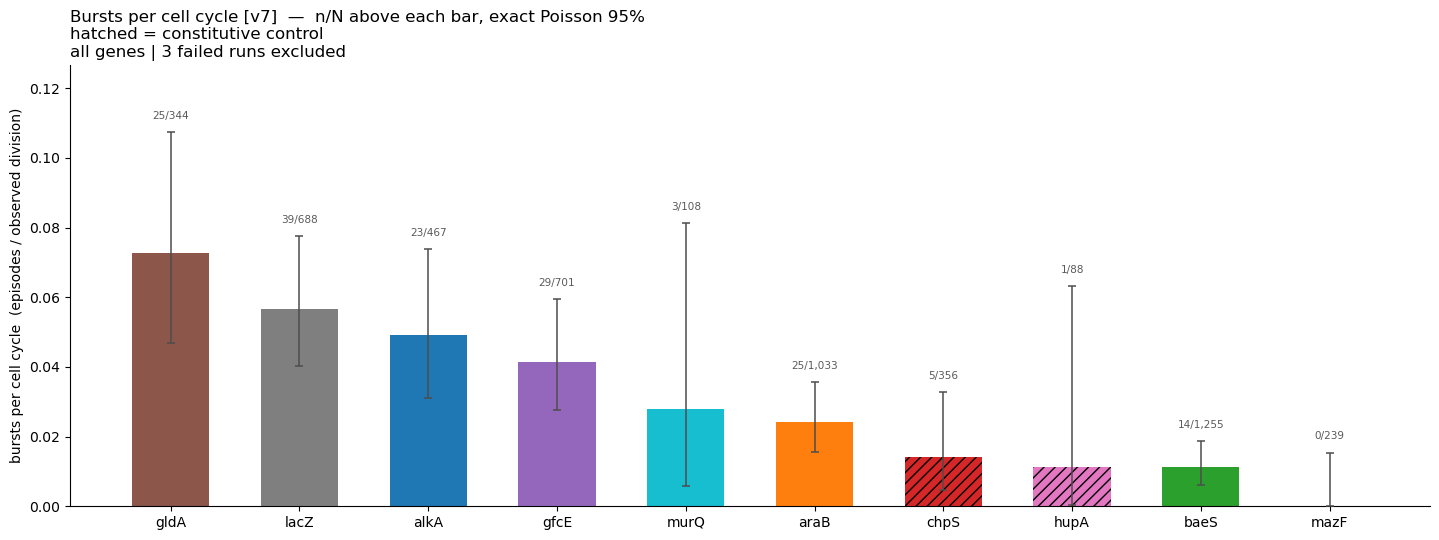

In [22]:
rate7 = F.bursts_per_cell_cycle(burst_union, divisions, version='v7')
print('bursts per cell cycle [v7]\n')
print(rate7.to_string())
F.plot_bursts_per_cell_cycle(burst_union, divisions, version='v7')

v6 -> v7, per gene

          v6  v6_n      v7  v7_n   delta  delta_n  n_divisions  constitutive
gene                                                                        
gldA  0.0698    24  0.0727    25  0.0029        1          344         False
lacZ  0.0552    38  0.0567    39  0.0015        1          688         False
alkA  0.0493    23  0.0493    23  0.0000        0          467         False
gfcE  0.0399    28  0.0414    29  0.0015        1          701         False
murQ  0.0185     2  0.0278     3  0.0093        1          108         False
araB  0.0213    22  0.0242    25  0.0029        3         1033         False
chpS  0.0140     5  0.0140     5  0.0000        0          356          True
hupA  0.0000     0  0.0114     1  0.0114        1           88          True
baeS  0.0112    14  0.0112    14  0.0000        0         1255         False
mazF  0.0000     0  0.0000     0  0.0000        0          239          True


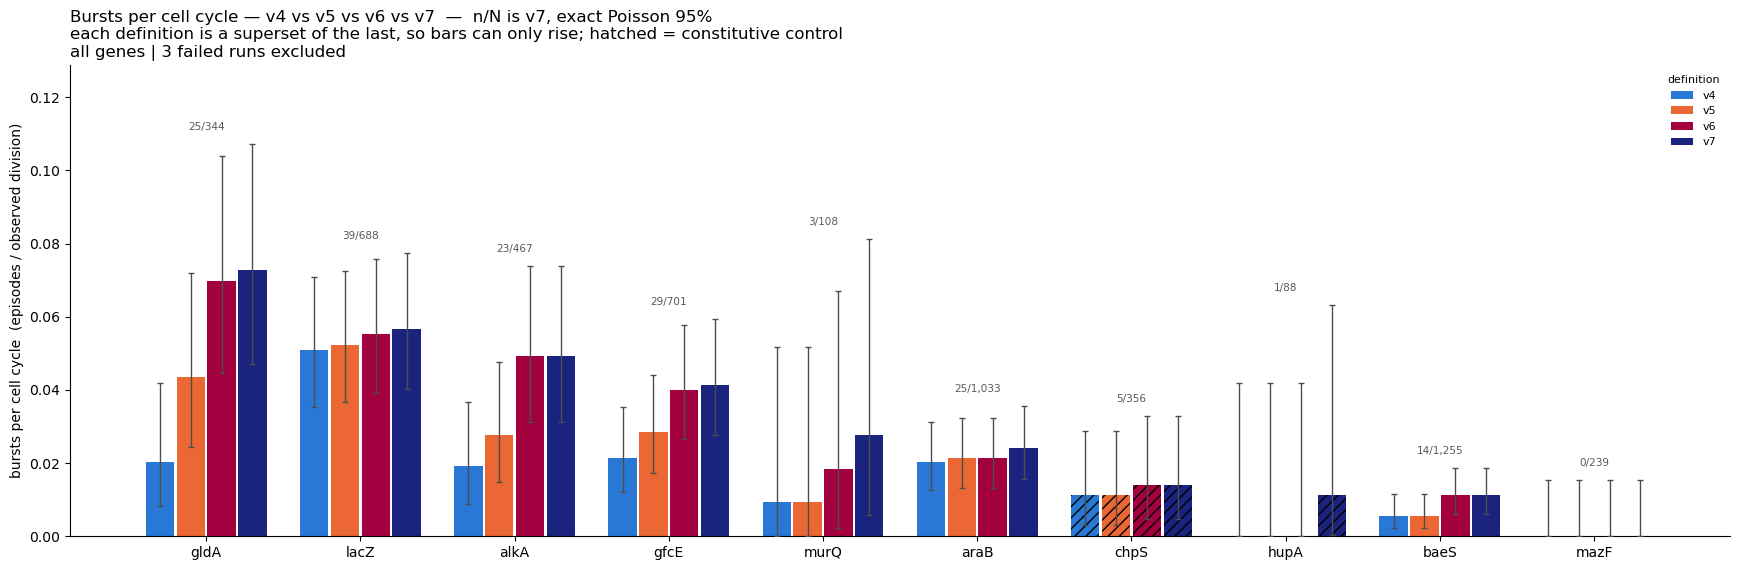

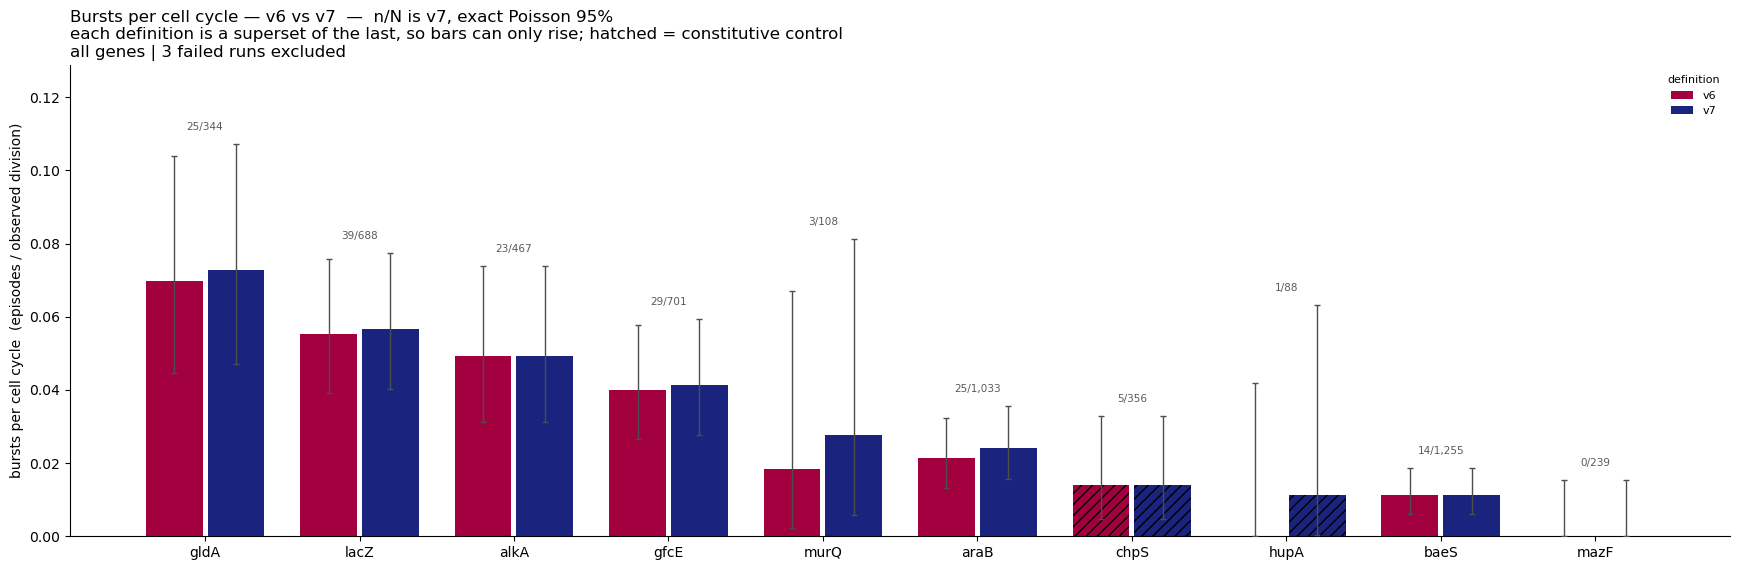

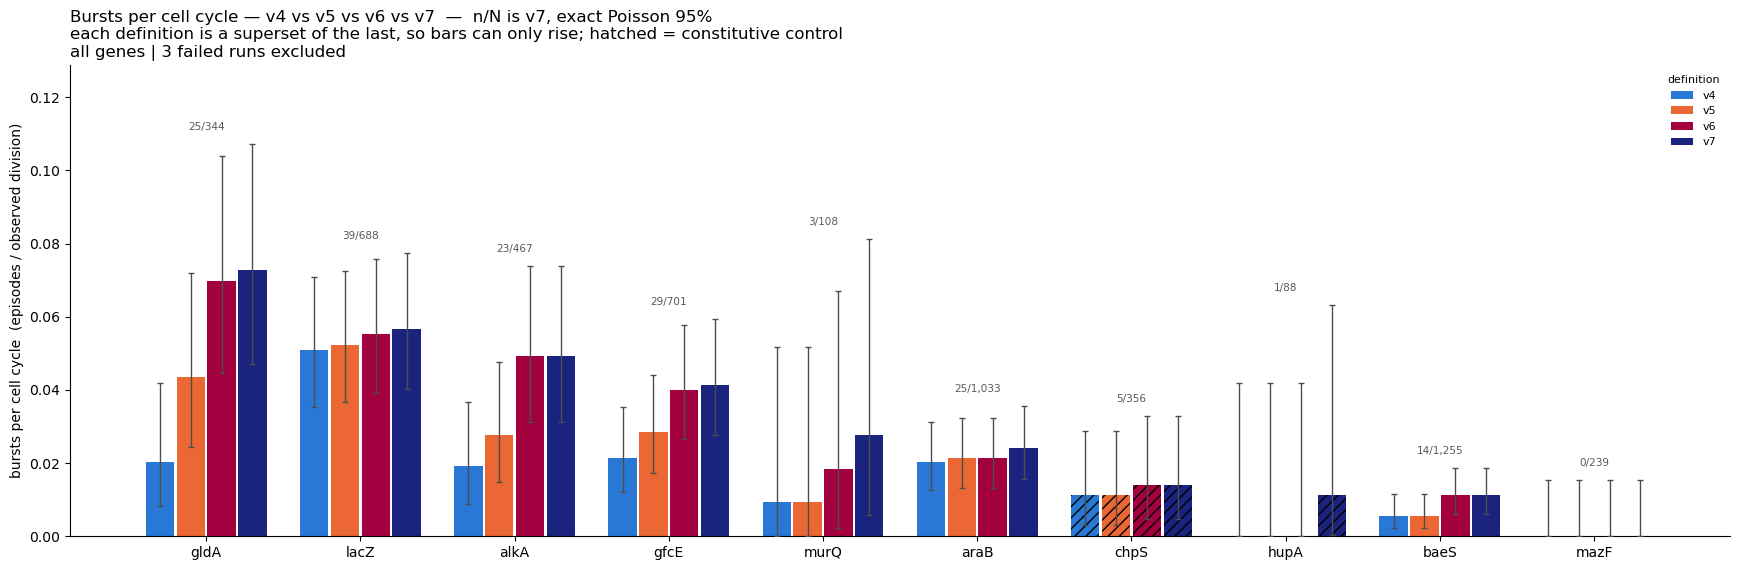

In [23]:
# The comparison the definition change is actually about.
cmp67 = F.burst_rate_comparison(burst_union, divisions, versions=('v6', 'v7'))
print('v6 -> v7, per gene\n')
print(cmp67[['v6', 'v6_n', 'v7', 'v7_n', 'delta', 'delta_n', 'n_divisions',
             'constitutive']].to_string())
F.plot_burst_rate_comparison(burst_union, divisions, versions=('v6', 'v7'))

# And the whole ladder, so v7's increment is legible against the earlier ones.
F.plot_burst_rate_comparison(burst_union, divisions, versions=('v4', 'v5', 'v6', 'v7'))

### ⚠ What the rate does to the ranking

`gldA` stays top and `mazF` stays at a hard zero, but **v7 moves a constitutive control off the
bottom of the table**: hupA goes from 0.0000 (tied last with mazF under v6) to **0.0114**, which
places it **8th, above baeS at 0.0112**. One event did that, on the smallest denominator in the
set (88 divisions).

Do not read that as hupA bursting more than baeS. The two point estimates differ by 0.0002 and
hupA's interval is 0.0003–0.0633 against baeS's 0.0061–0.0187 — they are not distinguishable, and
hupA's is wide precisely because it rests on a single event over 88 divisions. What the reordering
does show is the cost of the shipped κ: the claim "the constitutive controls are bottom under
every definition" held from v1 through v6 and **does not survive v7**. `bursts.md` §11 records it.

`tukey_iqr_k=4.4` restores it — hupA returns to 0 and the ordering is v6's — at the price of 4
events instead of 8.

---
## Where this leaves the hypothesis

**The premise held, and the outcome is better than round 1's.** 146 of 255 trenches cannot reach
their gene's bar, so a per-trench view was worth building. But the useful statistic turned out
not to be a re-scoped *height* bar — which is what all four prior attempts changed, and what
`bursts.md` §8 records as not shipped.

What works is a **shape** statistic on the trench's own distribution:

1. **Tukey's fence reaches both documented near-misses.** gfcE 013/153 (2 flagged frames of 300,
   one of them the v6 peak) and alkA 001/1192 (4 of 275, including the v5 peak) were invisible to
   every height bar at every scope. Round 1 had to present them as negative controls.
2. **It ranks the constitutive controls 6th/7th/8th of 10**, with lacZ top and baeS bottom —
   the shipped ranking's shape, from no shared machinery.
3. **`max p99/p50` separates the controls outright**, band `(2.85, 3.51]`, and needs no
   denominator floor because raw fluorescence is strictly positive here.

**What it still cannot do**, and why nothing above writes an event CSV: a distribution has no
notion of a *rise*, and prominence is the load-bearing criterion (`bursts.md` §4). Per trench the
controls are not at zero. And a flagged count is not an event count — araB 003/1598 flags 44
cell-frames over 33 frames in two separated stretches, so the count mixes magnitude, duration and
co-bright cell count all at once.

### The follow-up this points at

Not a fifth baseline. Take §4's leads and §5's fence-only trenches and put them through a
criterion that measures a rise. Two concrete steps:

- **Add `baseline_cols` to `Bu.burst_candidates`.** It always calls `compute_baselines`, so it
  cannot currently audit candidates under anything but the `(gene, experiment)` baseline — which
  is the gap that stops the leads here being scored by prominence and fold.
- **Consider a `tukey` route for a v7**, OR'd in like v5's `fold` and v6's `fold_left` were, with
  the same discipline: a sweep on the `1.5·IQR` multiplier, the hupA/mazF acceptance test at
  every setting, and a strict-superset check against v6. The band would need establishing —
  `1.5` is the textbook value here, not a measured one.

**Read §5 the right way round.** The 122 fence-only trenches are not 122 missed bursts. The
fence flags something in 220 of 255 trenches, so that list is mostly the tail of ordinary
scatter — and hupA, mazF and chpS are in it. The result worth keeping from §5 is the
**agreement**: 92% of v6, and a rank correlation of 0.84 from two routes with no shared
machinery.

---
## 9 · Burst v9 — any-signal on the FIJI-transformed images

A different **measurement**, not another rule on `fluor_per_ms`. §6 promoted a distribution
statistic to a route; this section drops thresholds entirely, because the image transform has
already done the thresholding.

The chain (`generate_kymograph_viewer.render_fluor_fiji`, measured as numbers by
`track_displacement.compute_fiji_fluor`) is: clip at **0.25 × each trench's own max** → ImageJ
median **r = 2.0** on the *assembled* kymograph → **no** small-object removal (that step was turned off on 090926; it had become a detection parameter rather than a denoiser). It
reproduces a manual FIJI session bit-for-bit on `fluor_kymos/008_1488.tif`. Whatever survives
is the candidate set, so **any** nonzero cell-frame is a burst candidate — and that needs no
choice of statistic, since `fiji_mean > 0`, `fiji_max > 0` and `fiji_frac > 0` are the
*identical* 32,979 cell-frames.

Deduplication is spatial-temporal connected components, not `merge_concurrent_bursts`: lit
cell-frames within **±2 frames** and **1.5 cell lengths** in y are one event, reported at
onset. The y tolerance scales with the frame gap because a track drifts −4.7 px/frame (−17 at
p10), so a fixed tolerance would fragment any advecting burst. The cell length is the
**trench's own** median `axis_major_length`, which keeps it scale-free for the ~⅓-scale
`DUMM_giTG66_Glucose_012325`.

**Why v9 is not comparable to v4–v7.** Those are nested rules on one column, each a strict
superset of the last. v9 reads a different image, so it is neither a superset nor a subset —
it recovers 76% of v6's cell-frames and adds many of its own. Do not put it on a
`burst_rate_comparison` axis with them and read the difference as a definition change.

*Reads `data/divisions_082026.csv` for the denominator. That is a derived divisions table, not
a cell-pair table, so this notebook stays pair-free.*

In [ ]:
# The FIJI-transformed per-cell values. Sparse by construction: the floor is 25% of each
# trench's OWN max, so a cell only registers when it clears a quarter of its trench's
# brightest pixel.
FIJI_CSV = f'{REPO_ROOT}/data/fiji_fluor_nospeckle_090926.csv'
fiji = pd.read_csv(FIJI_CSV, dtype={'experiment_name': str, 'FOV': str, 'trench_id': str})

CELL_KEY = F.KYMO_KEY + ['track_id', 'time_frame']
lit_cells = clean.merge(fiji, on=CELL_KEY, how='left', validate='one_to_one')
lit_cells = lit_cells[lit_cells['fiji_mean'].notna()].copy()

# A NaN here would be silent: compute_baselines would return a NaN median and find_peaks
# would return nothing for every trench, with no error. v9 does not use that path, but the
# assert is cheap and the failure mode is expensive.
assert lit_cells['fiji_mean'].notna().all(), 'NaN in fiji_mean'

_lit = lit_cells['fiji_mean'] > 0
print(f'{len(lit_cells):,} cell-frames over {lit_cells.groupby(F.KYMO_KEY).ngroups} kymographs')
print(f'lit (any signal): {int(_lit.sum()):,} ({100 * _lit.mean():.1f}%)')
print('"any signal" is one set on all three statistics: '
      f'{bool(((lit_cells.fiji_mean > 0) == (lit_cells.fiji_max > 0)).all())}')

# The lit fraction runs INVERSELY to burstiness, which is what the gate exploits.
_lf = (lit_cells.assign(lit=_lit).groupby(F.KYMO_KEY + ['gene'])['lit'].mean()
       .reset_index().groupby('gene')['lit'].agg(['count', 'min', 'median', 'max']))
print('\nlit fraction per trench, by gene (hupA/mazF/chpS are the constitutive controls)\n')
print(_lf.round(3).to_string())

In [ ]:
# v10 = burst v5's rule with ONE substitution: the baseline. attach_fiji_scale puts
# median at 0 and scale at the trench's own brightest cell-mean, so k / k_prom are fractions
# of that peak rather than MAD multipliers. Everything else -- envelope, window, episode
# merge -- is v5 verbatim, which is why detect_bursts needs no new code path.
_scaled = Bu.attach_fiji_scale(lit_cells)
v10, _ = Bu.run_burst_detection_any(
    _scaled, Bu.BURST_DEF_V10, baseline_cols=('_base_med', '_base_scale'))

v6, _ = Bu.run_burst_detection_any(clean, Bu.BURST_DEF_V6)
_S = lambda d: set(map(tuple, d[F.KYMO_KEY + ['track_id', 'time_frame']]
                       .astype({'track_id': int, 'time_frame': int}).values))
REG = {('CL008_giTG068_072925', '003', '1598'),
       ('CL008_giTG068_072925', '007', '821'),
       ('DUMM_giTG059_060_061125', '008', '1488')}
_reg = {t[:3] for t in _S(v10)} & REG
_noscale = int(_scaled.groupby(F.KYMO_KEY)['_base_scale'].first().isna().sum())

print(f"v10  k={Bu.BURST_DEF_V10['k']} (height)  k_prom={Bu.BURST_DEF_V10['k_prom']} (rise), "
      f"both as fractions of the trench peak")
print(f'  {len(v10)} events over {v10.groupby(F.KYMO_KEY).ngroups} trenches '
      f'({_noscale} trenches have max fiji_mean == 0 and are skipped)')
print(f'  regression trenches: {len(_reg)}/3')
print(f'  constitutive controls: hupA={int((v10.gene == "hupA").sum())}, '
      f'mazF={int((v10.gene == "mazF").sum())}, chpS={int((v10.gene == "chpS").sum())}')
print(f'  routes: {v10.route.value_counts().to_dict()}   '
      f'(fold is OFF -- these traces rise from 0, so max(left,right) > 0 always fails)')

# The number that matters: v10 reports the same representative frame v6 does, so the two
# can be compared event by event -- which the any-signal v9 could not be.
print(f'\n  v6 events matched at the EXACT frame: {len(_S(v10) & _S(v6))}/{len(_S(v6))}'
      f'   (v9 managed 16, reporting onset where v6 reports the peak)')

# Frozen sets must be untouched by any of this -- including the relaxed baseline assert.
_ba = F.load_bursts(f'{REPO_ROOT}/data/bursts_082026.csv', version=None)
for _v, _want in (('v1', 73), ('v2', 89), ('v3', 89)):
    _b, _ = Bu.run_burst_detection_any(clean, Bu.BURST_DEFS[_v])
    assert _S(_b) == _S(_ba[_ba[f'burst_{_v}']]) and len(_b) == _want, _v
assert len(v6) == 156
print('\nregression OK -- v1/v2/v3 still reproduce bursts_082026.csv, v6 still 156')

In [ ]:
# Per gene, and why v5's own baseline could not be reused.
print('events per gene\n')
print(v10.gene.value_counts().sort_index().to_string())

# The collapse, quantified. This is why k/k_prom are fractions of the trench peak.
_b = F.compute_baselines(lit_cells, fluor_col='fiji_mean')
_coll = _b[_b['mad_scale'] <= 1e-5]
print(f'\n(gene, experiment) median+MAD baseline on fiji_mean: '
      f'{len(_coll)} of {len(_b)} groups COLLAPSE (median 0, scale floored at 1e-6)')
print(f'  collapsed genes: {sorted(_coll.reset_index()["gene"].unique())}')
print('  -> height = median + 4*scale is ~0 there, so every local maximum would qualify.')
print('  Measured: collapsed-baseline trenches fire on 74.1% of their local maxima against')
print('  42.9% for healthy ones, and v5 unmodified gives 1037 events of which ~503 are')
print('  effectively unthresholded. Hence attach_fiji_scale.')

F.plot_burst_counts(F.load_bursts(f'{REPO_ROOT}/data/bursts_v10_090926.csv', version='v10'),
                    version='v10', by_experiment=False, save=False)

In [ ]:
# Rate per observed cell cycle. divisions_082026.csv is a derived divisions table, so this
# notebook stays pair-free.
divisions = pd.read_csv(f'{REPO_ROOT}/data/divisions_082026.csv', dtype=F.READ_DTYPES)
bursts_v10 = F.load_bursts(f'{REPO_ROOT}/data/bursts_v10_090926.csv', version='v10')

rate9 = F.bursts_per_cell_cycle(bursts_v10, divisions, version='v10')
print('bursts per cell cycle [v10]\n')
print(rate9.to_string())
F.plot_bursts_per_cell_cycle(bursts_v10, divisions, version='v10', save=False)

### What v10 says

**352 events, 3/3 regression trenches, hupA 0**, and — the number that matters — **91 of
156 v6 events matched at the EXACT frame**, against v9's 16. Keeping v5's envelope-and-peak
machinery means v10 reports the same representative frames v6 does, so the two are directly
comparable event by event in a way the any-signal rule never was.

Per gene: baeS 90, gfcE 54, araB 51, gldA 39, chpS 35, alkA 30, lacZ 28, mazF 13, murQ 12.

Three caveats, and the first is the important one:

- **The control margin is narrower than v9's.** hupA is 0 only for `k ≥ 0.60` at this
  `k_prom`, and only two points in that band were tested — not a fine grid. mazF (13) and
  chpS (35) are **not** zero. v9 held hupA at 0 across a 0.60–0.90 plateau with mazF 9. So
  v10 buys frame-level agreement with v6 and pays for it in control cleanliness; if you need
  the cleaner controls, v9 is still on disk.
- **8 trenches have no usable scale** (max `fiji_mean` = 0) and are skipped.
- **`fold_prom` is inert** on this column and switched off: these traces rise from exactly 0,
  so the fold route's `max(left_base, right_base) > 0` guard always fails. Measured — the
  event set is identical with and without it. The whole 352 come by the `absolute` route,
  which here means "clears 0.60 of the trench peak and rose by 0.40 of it".

**Do not read `352 vs 156` as a definition change.** Different image, different measurement.

---
## 10 · Burst v11 — seed on each trench's own lit distribution

v9 and v10 are opposite errors on the same measurement.

**v10's bar is one order statistic.** It is `0.60 x P`, `P` the trench's single brightest
cell-mean, so it moves with whatever that trench's largest excursion happens to be. It returns a
**median of one event per trench**, and in **157 of the 247 lit trenches it sits above that
trench's own lit Tukey fence** — stricter than "an outlier among this trench's own lit values",
so second and third excursions cannot register. The same self-reference cuts the other way:
**54 of its 352 events are in trenches whose entire maximum is below 1 count.**

**v9 has no bar at all** — and its poor frame agreement was misdiagnosed. Reporting the *same*
events at their peak instead of their onset takes it from 13/156 to **89/156**, level with v10's
91. The candidate set was never the problem.

v11 keeps v9's structure and fixes both: a **seed** clears its own trench's `median + 4*MAD`
taken over that trench's **lit cell-frames only**, seeds cluster by v9's rule verbatim, the event
is reported at its **peak**, and a cluster must span **>= 2 frames**.

Conditioning on lit is the whole idea. v8 died because median and MAD were estimated over a
**zero-inflated** column (49% exact zeros -> median 0, MAD floored at 1e-6, bar ~ 4e-6).
Restricting the estimator to the positive part removes the inflation, and unlike the rejected
`fiji_vmax - fiji_vmin` it stays dimensionally matched. **`bursts.md` section 7 has the full
sweep**; this section reproduces the headline numbers and the regression gate.

In [ ]:
# The diagnosis, measured -- both halves of it.
_v9p = Bu.detect_bursts_seeded(lit_cells.assign(_lit_thresh=0.0), lit_gate=0.90, min_frames=1,
        constitutive_genes=set(Bu.BURST_DEF_V9['constitutive_genes']))
_v9, _ = Bu.run_burst_detection_any(lit_cells, Bu.BURST_DEF_V9)
print('v9 candidate set + clustering, reported at the ONSET (what v9 ships): '
      f'{len(_S(_v9) & _S(v6))}/156 v6 events at the exact frame')
print('                              ... reported at the PEAK:               '
      f'{len(_S(_v9p) & _S(v6))}/156      (v10: {len(_S(v10) & _S(v6))}/156)')
print('Same events, same clustering, one line different -- so v9 was never out-detected.\n')

_tmax = lit_cells.groupby(F.KYMO_KEY)['fiji_mean'].max()
_nz = lit_cells[lit_cells.fiji_mean > 0].groupby(F.KYMO_KEY)['fiji_mean']
_q1, _q3 = _nz.quantile(.25), _nz.quantile(.75)
_c = pd.DataFrame({'tmax': _tmax, 'bar': 0.60 * _tmax,
                   'fence': _q3 + 1.5 * (_q3 - _q1)}).dropna()
_c = _c[_c.tmax > 0]
print(f"v10's bar sits ABOVE the trench's own lit Tukey fence in "
      f'{int((_c.bar > _c.fence).sum())} of {len(_c)} lit trenches')
print(f'v10 events per trench: median {v10.groupby(F.KYMO_KEY).size().median():.0f}, '
      f'mean {v10.groupby(F.KYMO_KEY).size().mean():.2f}')
_j = v10.set_index(F.KYMO_KEY).join(_tmax.rename('tmax')).reset_index()
print(f'v10 events in trenches whose OWN max is < 1 count: {int((_j.tmax < 1).sum())} of {len(v10)}')

In [ ]:
# v11. attach_lit_baseline_for, never the raw attach_lit_baseline: the bar lives in a COLUMN,
# so pairing a frame with the wrong definition would silently report a different event set.
# There is an assert for exactly that -- it is the same class of silent no-op as baseline_keys.
_seeded = Bu.attach_lit_baseline_for(lit_cells, Bu.BURST_DEF_V11)
v11, _ = Bu.run_burst_detection_any(_seeded, Bu.BURST_DEF_V11)

_d = Bu.BURST_DEF_V11
print(f"v11  seed_rule={_d['seed_rule']} k={_d['k']} (median + k*MAD over the LIT values only), "
      f"lit_gate={_d['lit_gate']}, min_frames={_d['min_frames']}")
print(f'  {len(v11)} events over {v11.groupby(F.KYMO_KEY).ngroups} trenches')
print(f'  regression trenches: {len({t[:3] for t in _S(v11)} & REG)}/3')
print('  constitutive controls: ' + ', '.join(
    f'{g}={int((v11.gene == g).sum())}' for g in ('hupA', 'mazF', 'chpS')))
print(f'  routes: {v11.route.value_counts().to_dict()}')
print(f'  events per trench: median {v11.groupby(F.KYMO_KEY).size().median():.0f}, '
      f'mean {v11.groupby(F.KYMO_KEY).size().mean():.2f}, '
      f'max {v11.groupby(F.KYMO_KEY).size().max()}')

def _cov(d, ref, w=5):
    by = {}
    for e, f, t, tr, fr in _S(d):
        by.setdefault((e, f, t), []).append(fr)
    return sum(1 for e, f, t, tr, fr in ref
               if any(abs(x - fr) <= w for x in by.get((e, f, t), []))) / len(ref)

print(f'\n  v6 events at the exact frame: {len(_S(v11) & _S(v6))}/156   '
      f'within +/-5: {_cov(v11, _S(v6)):.3f}   (v10: {len(_S(v10) & _S(v6))}/156, '
      f'{_cov(v10, _S(v6)):.3f})')
print(f'  v10 events kept at the exact frame: {len(_S(v11) & _S(v10))}/{len(v10)}')

# The frozen sets must be untouched by any of this.
for _v, _want in (('v1', 73), ('v2', 89), ('v3', 89)):
    _b, _ = Bu.run_burst_detection_any(clean, Bu.BURST_DEFS[_v])
    assert _S(_b) == _S(_ba[_ba[f'burst_{_v}']]) and len(_b) == _want, _v
assert len(v6) == 156 and len(v10) == 352
print('\nregression OK -- v1/v2/v3 still reproduce bursts_082026.csv; v6 156; v10 352')

In [ ]:
# The two sweep results worth keeping in the notebook: the rule that FAILS, and the axis
# that had never been swept. Full tables in bursts.md section 7.
print('The lit TUKEY fence fails the regression -- 1 of 3 at every multiplier. Why:\n')
for _e, _f, _t in sorted(REG):
    _g = lit_cells[(lit_cells.experiment_name == _e) & (lit_cells.FOV == _f)
                   & (lit_cells.trench_id == _t)]
    _v = np.sort(_g.fiji_mean[_g.fiji_mean > 0].to_numpy())
    _q1, _q3, _m = np.percentile(_v, 25), np.percentile(_v, 75), np.median(_v)
    print(f'  {_e} {_f}/{_t}: {len(_v)}/{len(_g)} lit ({len(_v)/len(_g):.0%})  peak {_v.max():.3f}'
          f'   tukey {_q3 + 1.5*(_q3-_q1):.3f}   median+4MAD '
          f'{_m + 4*1.4826*np.median(np.abs(_v-_m)):.3f}')
print('\nOn a 5%-lit trench the burst IS a large share of the lit values, so it inflates Q3 and')
print('the IQR together and the fence lands ABOVE the burst. The median/MAD is not dragged up.')

print('\nmin_frames -- a NEW axis; bursts.md records no swept duration gate anywhere:\n')
for _mf in (1, 2, 3, 4):
    _b = Bu.detect_bursts_seeded(_seeded, lit_gate=_d['lit_gate'], min_frames=_mf,
            constitutive_genes=set(_d['constitutive_genes']))
    print(f'  min_frames={_mf}: {len(_b):4d} events, hupA {int((_b.gene=="hupA").sum())}, '
          f'mazF {int((_b.gene=="mazF").sum())}, chpS {int((_b.gene=="chpS").sum())}, '
          f'v6 exact {len(_S(_b) & _S(v6))}')
print('\nfrac_min on fiji_frac -- never thresholded by any definition before. Measured INERT:')
_b = Bu.detect_bursts_seeded(_seeded, lit_gate=_d['lit_gate'], min_frames=2, frac_min=0.2,
        constitutive_genes=set(_d['constitutive_genes']))
print(f'  frac_min=0.2: {len(_b)} events (vs {len(v11)}), mazF {int((_b.gene=="mazF").sum())}, '
      f'chpS {int((_b.gene=="chpS").sum())} -- the controls do not move at all.')

### What v11 says

**469 events, 3/3 regression trenches, hupA 0, mazF 9, chpS 34.** Against v10: a third more
events at a **median of two per trench instead of one**, better on both non-zero controls
(mazF 9 vs 13, chpS 34 vs 35), better ±5 coverage of v6 (0.763 vs 0.692), and two fewer exact
frames (89 vs 91). It costs 28 trenches — the ones whose only excursions are single-frame or
below their own trench's bar.

**Be honest about what is doing the work.** hupA is 0 because `lit_gate` **discards all six of
its trenches wholesale**, not because the bar discriminates inside them; hupA is lit in 99.9% of
its cell-frames. chpS still ranks 5th of ten by rate, so **v9 remains the only FIJI-values
definition under which all three constitutive genes rank last.** And `k = 4.0` sits on no
plateau — the sweep is monotone in both directions, so it is a recall/control trade knob set by
precedent (it is the multiplier v1–v7 use) rather than a fitted value.

v11 is neither a superset nor a subset of v9 or v10. Do not put it on a `burst_rate_comparison`
axis with v4–v7.

*Adjudication:* `data/burst_worklist_v11_090926.csv` lists every event either definition finds,
tagged `both` / `v11_only` / `v10_only`, with each peak's percentile within its own trench's lit
values and the **absolute viewer frame** — so a candidate can be opened in the viewer directly.
The 250 `v11_only` rows are the new claims to check; the 133 `v10_only` rows are what v11
drops.

---
## 11 · Hand-labelled ground truth

Sections 9 and 10 reported 802 and 469 events. Neither number has a **denominator**. §9's
acceptance test — three constitutive controls, three regression trenches — catches gross
failures but cannot express recall or precision, so "v11 finds 33% more events than v10" has
been an observation about counts, not about correctness.

`mmtrack/burst_labels.py` is the fix, and it is **not a definition**: nothing in it detects
anything, and it must never enter `BURST_DEFS`.

**The seed is v7 ∪ v11, and it already exists.** Because v5 ⊂ v6 ⊂ v7 strictly,
`data/bursts_viewer_v11_090926.csv`'s 541 rows *are* that union (164 + 469 − 92 shared).

**What this can and cannot measure.** Precision is measurable — every seeded row is an event
some definition claimed, so the fraction of a definition's *labelled* events marked `yes` is
exactly its precision. **Recall over all rows is an upper bound**, because the table was seeded
from the very definitions being scored: a burst they all miss is present only if the labeller
volunteers it. `sweep_trench` marks 15 gene-stratified trenches for *exhaustive* review, and
recall over those is unbiased. `evaluate` returns the two scopes as separate rows and never
averages them.

**This required a viewer change.** The identifier a labeller needs is the `track_id`, and it was
not readable: `render_labels_svg` drew one number per *lineage at its first appearance*, so the
id of a cell bursting at frame 80 had to be traced back through division connectors. It now
draws one label per **cell-frame**, and those ids are the ctc mask labels — the same `track_id`
the tables use. Rebuilt as `data/kymograph_viewer_v11_091026.html`.

*`bursts.md` §13 is the reference for the schema, the four silent failures the ingest catches,
and the recall-bias caveat. Read it before quoting any number from here.*

In [ ]:
import mmtrack.burst_labels as BL

TEMPLATE = f'{REPO_ROOT}/data/burst_labels_TEMPLATE_091026.csv'

# Regenerating is idempotent -- but it would BLANK any labels already entered, so only run
# this when starting a fresh pass.
REGENERATE = False
if REGENERATE:
    BL.write_label_template('data/burst_labels_TEMPLATE_091026.csv',
                            extra_csv='data/bursts_v11_090926.csv',
                            sweep_n=15, data_root=REPO_ROOT)

_t = pd.read_csv(TEMPLATE, dtype=str, keep_default_na=False)
print(f'{len(_t)} rows over {_t.groupby(F.KYMO_KEY).ngroups} trenches; '
      f"{int((_t.label.str.strip() != '').sum())} labelled so far")
print(f'  sweep trenches (review EXHAUSTIVELY): '
      f"{_t[_t.sweep_trench == 'True'].groupby(F.KYMO_KEY).ngroups}")
print(f'  fill in {BL.EDIT_COLS}; vocabulary {BL.LABELS}; blank = not reviewed')
print(f'  to append a missed burst: fill {BL.APPEND_COLS}, leave row_key blank')
print('\nThe frame to type is the ABSOLUTE viewer frame (the number under the phase layer),')
print('not time_frame -- the template carries both so the mapping is never done by hand.')

In [ ]:
# Ingest + score. Safe to run against a partly-labelled template: unlabelled rows are
# unreviewed, not negative, and simply do not enter any statistic.
labels, problems = BL.read_labels('data/burst_labels_TEMPLATE_091026.csv', clean,
                                  data_root=REPO_ROOT, strict=False)

if len(labels):
    v7_set = F.load_bursts(f'{REPO_ROOT}/data/bursts_viewer_v11_090926.csv', version='v7')
    v11_set = F.load_bursts(f'{REPO_ROOT}/data/bursts_v11_090926.csv', version='v11')
    ev = BL.evaluate(labels, {'v7': v7_set, 'v11': v11_set})
    print()
    print(ev[['definition', 'recall_scope', 'n_events_labelled', 'precision',
              'precision_lo', 'precision_hi', 'n_yes', 'recall_exact',
              'recall_within_5']].to_string(index=False))
    print()
    print(BL.label_summary(labels).to_string(index=False))
    labels.to_csv(f'{REPO_ROOT}/data/burst_labels_091026.csv', index=False)
    print(f'\nwrote data/burst_labels_091026.csv ({len(labels)} labelled rows)')
else:
    print('Nothing labelled yet -- open the viewer and the template, then re-run this cell.')
    print('Precision needs `no` verdicts as well as `yes`: a table of confirmations only')
    print('cannot distinguish a good definition from one that flags everything.')

---
## 12 · The trained classifier (v12)

Sections 9–11 reported event counts. §11 built the machinery for ground truth; this section has
the ground truth itself — **211 bursts identified by eye** in lacZ and gfcE over 60 trenches
reviewed *exhaustively*, so an unmarked cell-frame in one of them is a real negative.

For the first time there are precision and recall numbers, one-to-one matched. They are not
flattering to the rules: **v7 is the most precise (0.838) at recall 0.281; v11 reaches recall
0.429 at precision 0.592.** The classifier at its shipped threshold gets **precision 0.607 at
recall 0.739** — strictly dominating v11 on both axes — while never reaching v7's precision.

What earns the gain is the **temporal** feature block. Nothing in this codebase computed a
rolling window on fluorescence before; adding lineage-aware ones takes AUC 0.950 → 0.967. The
top feature is the causal fold against the trailing median, i.e. the per-cell-frame analogue of
v6's `fold_left`.

**Two failures, stated up front.** It fires 2 events in the certified burst-free trench at the
shipped threshold (0 at 0.90). And it is much worse than the rules on the constitutive controls
— hupA 23 / mazF 51 / chpS 77 against v11's 0 / 9 / 34 — because it has **never seen a control
gene**. Labelling a handful of hupA/mazF/chpS trenches is the highest-return next step.

*`bursts.md` §14 has the sweeps and the bands. Read it before quoting anything here.*

In [ ]:
import mmtrack.burst_training as BT

_fiji = pd.read_csv(f'{REPO_ROOT}/data/fiji_fluor_nospeckle_090926.csv',
                    dtype={'experiment_name': str, 'FOV': str, 'trench_id': str})
Xf = BT.featurize(clean.merge(_fiji, on=BT.CELL_KEY, how='left'))
FEATS = Xf.attrs['feature_cols']

labels, rejects = BT.load_hand_labels(cells=clean, data_root=REPO_ROOT)
reviewed = BT.reviewed_trenches(labels)
train = BT.build_training_table(Xf, labels, reviewed, mask_window=BT.MASK_WINDOW)

In [ ]:
# Out of fold, grouped by TRENCH -- a random split would train and test on the same burst.
oof, auc, ap = BT.cross_val_scores(train, FEATS)
_, auc_s, ap_s = BT.cross_val_scores(train, FEATS, shuffle_y=True)
print(f'cell-frame out-of-fold: AUC {auc:.4f}  PR-AUC {ap:.4f}')
print(f'  shuffled-label floor:  AUC {auc_s:.4f}  PR-AUC {ap_s:.4f}  '
      f'(base rate {train.y.mean():.4f}) -- the sanity check')

pr = BT.pr_curve(oof, labels, reviewed=reviewed)
print()
print(pr[pr.threshold.isin([0.3, 0.5, 0.6, 0.75, 0.85, 0.9, 0.95])].to_string(index=False))

In [ ]:
# The comparison that matters: the same greedy ONE-TO-ONE matcher for every definition.
# Counting 'any label within +/-k' lets one event claim several labels and inflates both
# numbers -- that error was made and corrected while building this.
_K = BT.CELL_KEY[:3]
print(f'{"model":22s} {"events":>6s} | {"TP":>4s} {"P":>6s} {"R":>6s}   (tol = 1 frame)')
def _row(nm, ev):
    ev = ev[[tuple(r) in reviewed for r in ev[_K].values]] if len(ev) else ev
    tp = BT.match_events(ev, labels, 1)
    print(f'{nm:22s} {len(ev):6d} | {tp:4d} '
          f'{tp/len(ev) if len(ev) else 0:6.3f} {tp/len(labels):6.3f}')
for _nm, _p, _c in (('v7', 'bursts_viewer_v11_090926.csv', 'burst_v7'),
                    ('v10', 'bursts_v10_090926.csv', 'burst_v10'),
                    ('v11', 'bursts_v11_090926.csv', 'burst_v11')):
    _t = pd.read_csv(f'{REPO_ROOT}/data/{_p}', dtype=F.READ_DTYPES)
    _t = _t[_t[_c].astype(str).str.lower().isin(('true', '1', 't', 'yes'))].assign(score=1.0)
    _row(_nm, _t[BT.CELL_KEY + ['score']].astype({'track_id': int, 'time_frame': int}))
for _thr in (0.60, 0.75, 0.90):
    _row(f'classifier @{_thr}', BT.score_to_events(oof, _thr))

# The certified burst-free trench, and the controls it has never seen.
_E = ('DUMM_giTG064_Glucose_022625', '015', '298')
for _thr in (0.75, 0.90):
    _ev = BT.score_to_events(oof, _thr)
    _n = len(_ev[(_ev.experiment_name == _E[0]) & (_ev.FOV == _E[1]) & (_ev.trench_id == _E[2])])
    print(f'\ncertified burst-free trench at thr {_thr}: {_n} events   (v7 0, v11 0, v10 1, v9 5)')

In [ ]:
# Fit on everything labelled, persist WITH the feature list, and score the whole dataset.
# (The shipped GNN saves a bare state dict and refits its scaler at inference -- train/serve
# skew. Not repeated here.)
import joblib, os
model, feat_cols = BT.fit_final(train, FEATS)
os.makedirs(f'{REPO_ROOT}/models', exist_ok=True)
THRESHOLD = float(pr.loc[pr.f1.idxmax(), 'threshold'])
joblib.dump({'model': model, 'feature_cols': feat_cols, 'threshold': THRESHOLD,
             'mask_window': BT.MASK_WINDOW, 'link_dt': BT.LINK_DT,
             'trained_on': BT.HAND_LABEL_CSV, 'n_labels': len(labels)},
            f'{REPO_ROOT}/models/burst_classifier_091026.joblib')

Xf['score'] = model.predict_proba(Xf[feat_cols].to_numpy(float))[:, 1]
events = BT.score_to_events(Xf, THRESHOLD)
print(f'threshold {THRESHOLD:.2f} -> {len(events)} events over '
      f'{events.groupby(_K).ngroups} trenches\n')
print(events.gene.value_counts().sort_index().to_string())
print('\nhupA/mazF/chpS are OUT-OF-SAMPLE and inflated: the model never saw a control gene.')